# Activation Commitment Manifold Report

This notebook runs the activation-side summary and reporting pass for the gridworld commitment experiment. It does **not** re-extract activations. It uses existing activation tables, behavior-side prefix metrics, feature arrays, and figures produced by the activation analysis scripts.


## 1. Introduction

Behavior-side analysis showed that action commitment changes during chain-of-thought reasoning: the forced final-JSON scoring distribution can sharpen, switch, or lock in as reasoning progresses. Activation-side analysis asks whether that behavioral commitment is reflected in the model's internal activation trajectories.

The core question is whether activation states during CoT reasoning encode the same evolving action commitment measured behaviorally, and whether this internal commitment can be detected before the model explicitly verbalizes an action token.


In [1]:
from __future__ import annotations

import json
import os
import shutil
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_colwidth", 120)

ACTIONS = ["UP", "DOWN", "LEFT", "RIGHT"]
ACTION_COLORS = {
    "UP": "#4C78A8",
    "DOWN": "#F58518",
    "LEFT": "#54A24B",
    "RIGHT": "#B279A2",
}


def find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents, Path("/Users/wws/SPAR_code")]:
        if (candidate / "outputs").exists() and (candidate / "scripts").exists():
            return candidate.resolve()
    return here


ROOT = find_repo_root()
OUT = ROOT / "outputs"
ACT_OUT = OUT / "activation"
FIG_ROOT = ROOT / "figures" / "activation"
REPORT_FIG_DIR = FIG_ROOT / "report"
REPORT_FIG_DIR.mkdir(parents=True, exist_ok=True)
REPORT_MD_PATH = ACT_OUT / "reports" / "final_activation_commitment_report.md"
REPORT_MD_PATH.parent.mkdir(parents=True, exist_ok=True)

SUMMARY: dict[str, object] = {}
FIGURE_RECORDS: list[dict[str, str]] = []
SECTION_NOTES: list[str] = []

print(f"Repository root: {ROOT}")
print(f"Report figures directory: {REPORT_FIG_DIR}")
print(f"Final markdown report path: {REPORT_MD_PATH}")


Repository root: /Users/wws/SPAR_code
Report figures directory: /Users/wws/SPAR_code/figures/activation/report
Final markdown report path: /Users/wws/SPAR_code/outputs/activation/reports/final_activation_commitment_report.md


In [2]:
def rel(path: Path) -> str:
    try:
        return str(path.relative_to(ROOT))
    except ValueError:
        return str(path)


def read_table(relative_path: str, *, optional: bool = True) -> pd.DataFrame | None:
    path = ROOT / relative_path
    if not path.exists():
        msg = f"Missing optional output: `{relative_path}`"
        if optional:
            display(Markdown(f"> {msg}"))
            SECTION_NOTES.append(msg)
            return None
        raise FileNotFoundError(path)
    try:
        if path.suffix.lower() == ".csv":
            df = pd.read_csv(path)
        elif path.suffix.lower() in {".json", ".jsonl"}:
            df = pd.read_json(path, lines=path.suffix.lower() == ".jsonl")
        else:
            df = pd.read_parquet(path)
        display(Markdown(f"Loaded `{relative_path}`: **{len(df):,} rows x {len(df.columns):,} columns**"))
        return df
    except Exception as exc:
        msg = f"Could not load `{relative_path}`: {type(exc).__name__}: {exc}"
        if optional:
            display(Markdown(f"> {msg}"))
            SECTION_NOTES.append(msg)
            return None
        raise


def maybe_nunique(df: pd.DataFrame | None, col: str) -> int | None:
    if df is None or col not in df.columns:
        return None
    return int(df[col].nunique(dropna=True))


def numeric_summary(df: pd.DataFrame | None, cols: list[str]) -> pd.DataFrame:
    if df is None:
        return pd.DataFrame()
    present = [c for c in cols if c in df.columns]
    if not present:
        return pd.DataFrame()
    return df[present].apply(pd.to_numeric, errors="coerce").describe().T


def copy_and_show_figure(section: str, relative_path: str, caption: str, axis_note: str, color_note: str | None = None, width: int = 900):
    src = ROOT / relative_path
    safe_name = f"{section.lower().replace(' ', '_').replace('/', '_')}__{src.name}"
    dst = REPORT_FIG_DIR / safe_name
    if not src.exists():
        msg = f"Missing figure for {section}: `{relative_path}`"
        display(Markdown(f"> {msg}"))
        SECTION_NOTES.append(msg)
        return None
    shutil.copy2(src, dst)
    rel_to_report = os.path.relpath(dst, REPORT_MD_PATH.parent)
    record = {
        "section": section,
        "source": relative_path,
        "copied_to": rel(dst),
        "markdown_rel": rel_to_report,
        "caption": caption,
        "axis_note": axis_note,
        "color_note": color_note or "Color encodes the variable named in the caption.",
    }
    FIGURE_RECORDS.append(record)
    display(Markdown(f"**{caption}**  \\\nAxes: {axis_note}  \\\nColor: {record['color_note']}  \\\nSaved copy: `{rel(dst)}`"))
    display(Image(filename=str(dst), width=width))
    return dst


def top_metric(metrics: pd.DataFrame | None, *, metric_col: str, value_col: str = "value", control: str | None = None, subset: str | None = None):
    if metrics is None or metric_col not in metrics.columns or value_col not in metrics.columns:
        return None
    df = metrics.copy()
    if control is not None and "control" in df.columns:
        df = df[df["control"].astype(str).eq(control)]
    if subset is not None and "subset" in df.columns:
        df = df[df["subset"].astype(str).eq(subset)]
    df = df[pd.to_numeric(df[value_col], errors="coerce").notna()]
    if df.empty:
        return None
    return df.sort_values(value_col, ascending=False).iloc[0]


## 2. Data

This section loads the canonical activation and behavior-side tables. The activation token index describes pre-reasoning, CoT-token, and post-reasoning activation timepoints. The aligned and feature metadata tables connect behavior prefixes to activation pointers and feature arrays. The behavior commitment files provide the q-distribution and lock-in metrics used as targets.


In [3]:
activation_token_index = read_table("outputs/activation/activation_token_index.parquet")
activation_behavior_aligned = read_table("outputs/activation/activation_behavior_aligned.parquet")
activation_feature_metadata = read_table("outputs/activation/activation_feature_metadata.parquet")
prefix_commitment = read_table("outputs/prefix_commitment_metrics.parquet")
permanent_lockin = read_table("outputs/followups/permanent_lockin_summary.parquet")

available_feature_layers = sorted({
    int(path.stem.split("_")[1])
    for path in (ACT_OUT / "features").glob("layer_*_delta_pre.npy")
    if len(path.stem.split("_")) == 4
    and path.stem.split("_")[0] == "layer"
    and path.stem.split("_")[1].isdigit()
    and path.stem.split("_")[2:] == ["delta", "pre"]
})
hidden_dim = None
feature_shape = None
if available_feature_layers:
    arr = np.load(ACT_OUT / "features" / f"layer_{available_feature_layers[0]:02d}_delta_pre.npy", mmap_mode="r")
    feature_shape = tuple(arr.shape)
    hidden_dim = int(arr.shape[1]) if arr.ndim == 2 else None

data_summary = {
    "activation_inventory_decision_steps": maybe_nunique(activation_token_index, "decision_id"),
    "activation_inventory_trajectories": maybe_nunique(activation_token_index, "trajectory_id"),
    "behavior_aligned_decision_steps": maybe_nunique(activation_feature_metadata, "decision_id") or maybe_nunique(prefix_commitment, "decision_id"),
    "behavior_aligned_trajectories": maybe_nunique(activation_feature_metadata, "trajectory_id") or maybe_nunique(prefix_commitment, "trajectory_id"),
    "activation_timepoints": len(activation_token_index) if activation_token_index is not None else None,
    "cot_tokens": int((activation_token_index["token_type"].astype(str) == "cot").sum()) if activation_token_index is not None and "token_type" in activation_token_index.columns else None,
    "num_feature_layers": len(available_feature_layers),
    "hidden_dim": hidden_dim,
    "feature_shape_example": feature_shape,
}
SUMMARY["data_summary"] = data_summary

display(pd.DataFrame([data_summary]).T.rename(columns={0: "value"}))

if activation_token_index is not None and "token_type" in activation_token_index.columns:
    token_type_counts = activation_token_index["token_type"].value_counts(dropna=False).rename("count").to_frame()
    SUMMARY["token_type_counts"] = token_type_counts.to_dict()["count"]
    display(Markdown("### pre_reasoning / cot / post_reasoning counts"))
    display(token_type_counts)

if activation_feature_metadata is not None and "agent_action" in activation_feature_metadata.columns:
    action_dist = activation_feature_metadata.drop_duplicates("decision_id")["agent_action"].value_counts().reindex(ACTIONS).fillna(0).astype(int)
    SUMMARY["action_distribution"] = action_dist.to_dict()
    display(Markdown("### Action distribution by decision"))
    display(action_dist.rename("decision_count").to_frame())


Loaded `outputs/activation/activation_token_index.parquet`: **2,373,402 rows x 19 columns**

Loaded `outputs/activation/activation_behavior_aligned.parquet`: **9,942 rows x 90 columns**

Loaded `outputs/activation/activation_feature_metadata.parquet`: **9,942 rows x 70 columns**

Loaded `outputs/prefix_commitment_metrics.parquet`: **9,942 rows x 42 columns**

Loaded `outputs/followups/permanent_lockin_summary.parquet`: **132 rows x 14 columns**

,value
activation_inventory_decision_steps,1276
activation_inventory_trajectories,95
behavior_aligned_decision_steps,132
behavior_aligned_trajectories,10
activation_timepoints,2373402
cot_tokens,2370850
num_feature_layers,12
hidden_dim,2880
feature_shape_example,"(9942, 2880)"


### pre_reasoning / cot / post_reasoning counts

,count
token_type,
cot,2370850
pre_reasoning,1276
post_reasoning,1276


### Action distribution by decision

,decision_count
agent_action,
UP,32
DOWN,36
LEFT,22
RIGHT,42


## 3. Activation representation

For each decision step, the activation-side analysis uses three conceptual states:

- `h_pre`: the pre-reasoning activation before CoT generation begins.
- `h_k`: the activation at CoT token or prefix position `k`.
- `h_post`: the post-reasoning activation after the CoT ends.

The main representation is `delta_pre = h_k - h_pre`. This subtracts the prompt-induced baseline state and emphasizes how the internal state changes during reasoning. Raw activations are retained as a robustness representation because they preserve the absolute state. Velocity, `h_k - h_{k-1}`, is retained because it emphasizes local step-to-step movement rather than accumulated displacement from the pre-reasoning state.


In [4]:
if activation_feature_metadata is not None:
    rep_cols = [c for c in activation_feature_metadata.columns if c.startswith("feature_file_layer_")]
    rep_counts = pd.Series(["_".join(c.split("_")[4:]) for c in rep_cols]).value_counts().rename("num_layer_files")
    display(rep_counts.to_frame())
    SUMMARY["representations"] = rep_counts.to_dict()


,num_layer_files
delta_pre,12
raw,12
unit_delta_pre,12
velocity,12


## 4. Layer-wise decoding

This section summarizes linear decoding across layers when `outputs/activation/layer_sweep_metrics.csv` is available. The required figures use layer index on the x-axis. The y-axis is the corresponding held-out decoding metric: behavior CLR R2, commitment R2, action balanced accuracy, or strict pre-action R2. Color/line style distinguishes target or representation when present.


In [5]:
layer_sweep_metrics = read_table("outputs/activation/layer_sweep_metrics.csv")
if layer_sweep_metrics is not None:
    display(layer_sweep_metrics.head())
    numeric_cols = ["r2_mean", "r2", "balanced_accuracy", "accuracy", "macro_f1"]
    display(numeric_summary(layer_sweep_metrics, numeric_cols))
    SUMMARY["layer_sweep_rows"] = len(layer_sweep_metrics)
else:
    display(Markdown("Layer-wise decoding metrics are not currently present; this section is skipped gracefully."))

for fig, caption, axis, color in [
    ("figures/activation/layer_sweep/r2_behavior_clr_by_layer.png", "Behavior CLR decoding by layer", "x = activation layer; y = cross-validated R2 for behavior CLR vector", "line/color identifies representation or subset if present"),
    ("figures/activation/layer_sweep/r2_commitment_by_layer.png", "Commitment decoding by layer", "x = activation layer; y = cross-validated R2 for commitment_to_final", "line/color identifies representation or subset if present"),
    ("figures/activation/layer_sweep/agent_action_accuracy_by_layer.png", "Agent action decoding by layer", "x = activation layer; y = balanced action decoding accuracy", "line/color identifies representation or subset if present"),
    ("figures/activation/layer_sweep/strict_pre_action_r2_by_layer.png", "Strict pre-action decoding by layer", "x = activation layer; y = strict pre-action decoding metric", "line/color identifies strict pre-action subset or representation if present"),
]:
    copy_and_show_figure("04_layer_wise_decoding", fig, caption, axis, color)


> Missing optional output: `outputs/activation/layer_sweep_metrics.csv`

Layer-wise decoding metrics are not currently present; this section is skipped gracefully.

> Missing figure for 04_layer_wise_decoding: `figures/activation/layer_sweep/r2_behavior_clr_by_layer.png`

> Missing figure for 04_layer_wise_decoding: `figures/activation/layer_sweep/r2_commitment_by_layer.png`

> Missing figure for 04_layer_wise_decoding: `figures/activation/layer_sweep/agent_action_accuracy_by_layer.png`

> Missing figure for 04_layer_wise_decoding: `figures/activation/layer_sweep/strict_pre_action_r2_by_layer.png`

## 5. Activation manifold

Each point in these plots is one CoT-prefix activation state. The x-axis is the first activation PCA component (`act_pca1`) and the y-axis is the second activation PCA component (`act_pca2`). Colors show final action, behavioral commitment, entropy commitment, progress, or strict pre-action action labels depending on the figure.


Loaded `outputs/activation/activation_manifold.parquet`: **9,942 rows x 74 columns**

,value
rows,9942
layers,[16]
representations,[delta_pre]


,count,mean,std,min,25%,50%,75%,max
act_pca1,9942.0,-2.455649e-08,11.643588,-2.093994e+01,-9.050533,-2.645772,6.682975,31.274897
act_pca2,9942.0,-1.289216e-07,9.569728,-2.093377e+01,-6.066301,-0.266985,5.281905,49.029919
commitment_to_final,9942.0,6.875132e-01,0.365888,3.224187e-08,0.345773,0.888490,0.997900,1.000000
entropy_commitment,9942.0,6.987704e-01,0.296663,1.629884e-02,0.438355,0.788203,0.988583,1.000000
progress,9942.0,5.017653e-01,0.292822,1.665834e-04,0.248578,0.504931,0.758342,1.000000


**Activation PCA colored by final agent action**  \
Axes: x = act_pca1; y = act_pca2  \
Color: final `agent_action`  \
Saved copy: `figures/activation/report/05_activation_manifold__pca_by_agent_action.png`

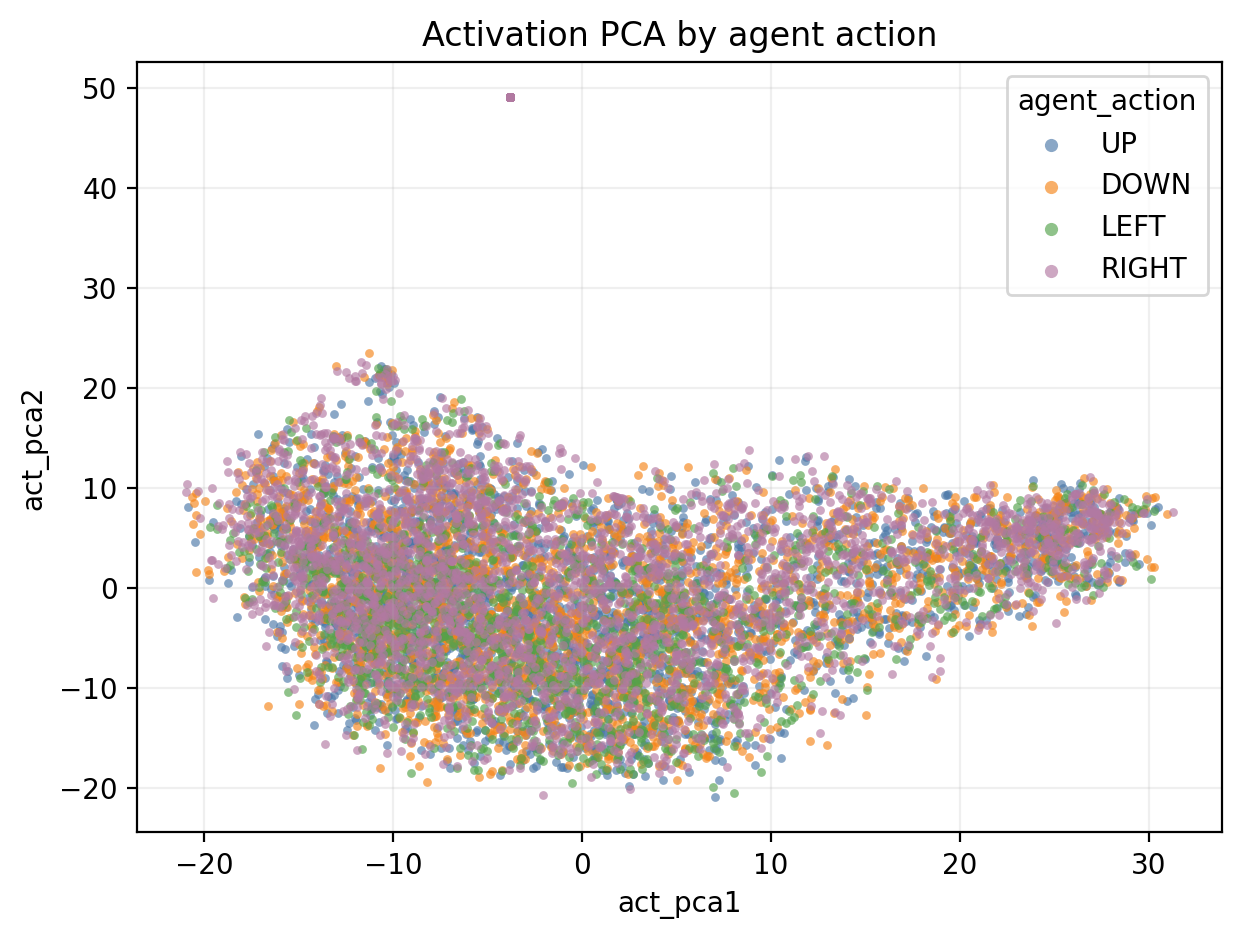

**Activation PCA colored by behavior commitment to final action**  \
Axes: x = act_pca1; y = act_pca2  \
Color: continuous `commitment_to_final`; darker/brighter values indicate higher commitment depending on the colormap  \
Saved copy: `figures/activation/report/05_activation_manifold__pca_by_commitment_to_final.png`

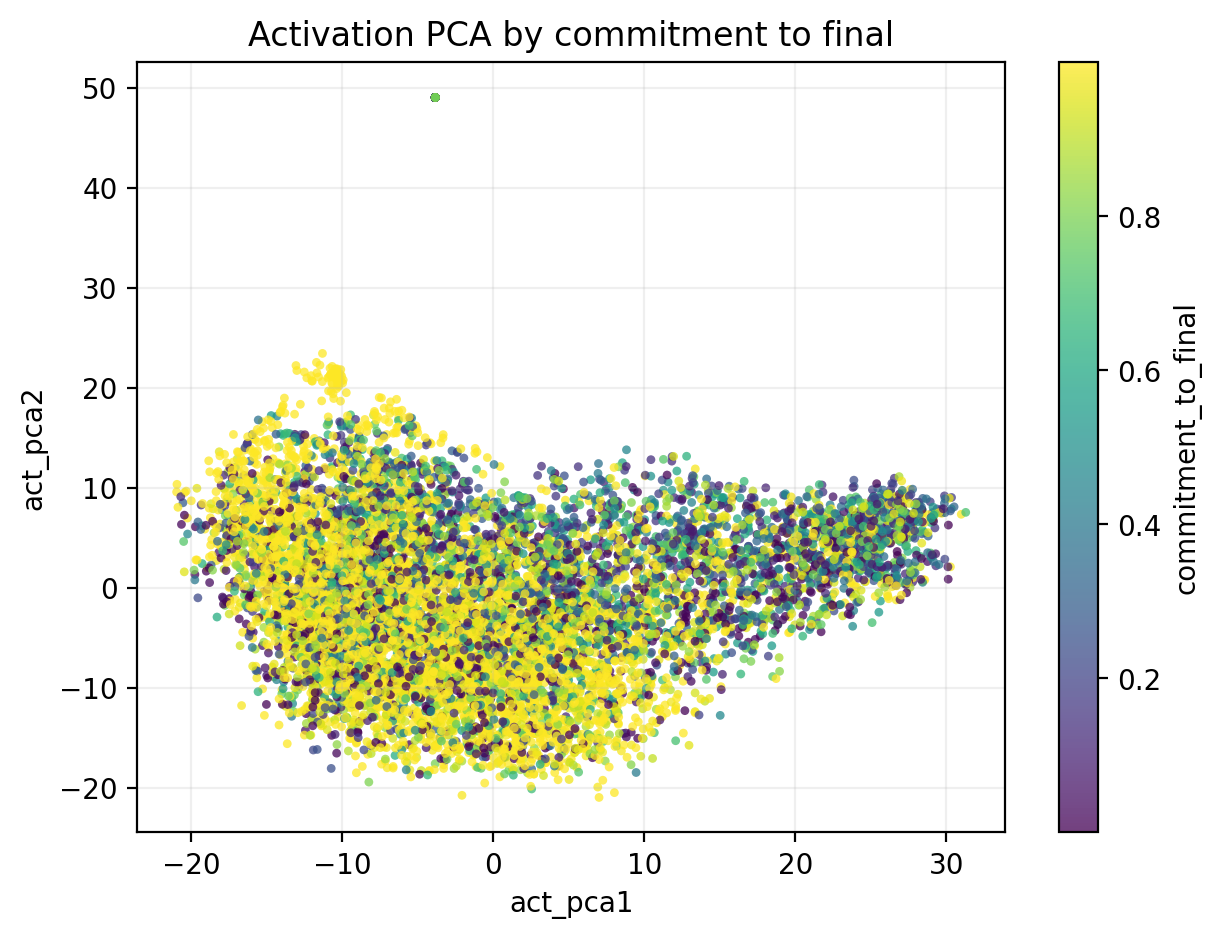

**Activation PCA colored by entropy commitment**  \
Axes: x = act_pca1; y = act_pca2  \
Color: continuous `entropy_commitment`; higher values mean lower entropy / sharper action distribution  \
Saved copy: `figures/activation/report/05_activation_manifold__pca_by_entropy_commitment.png`

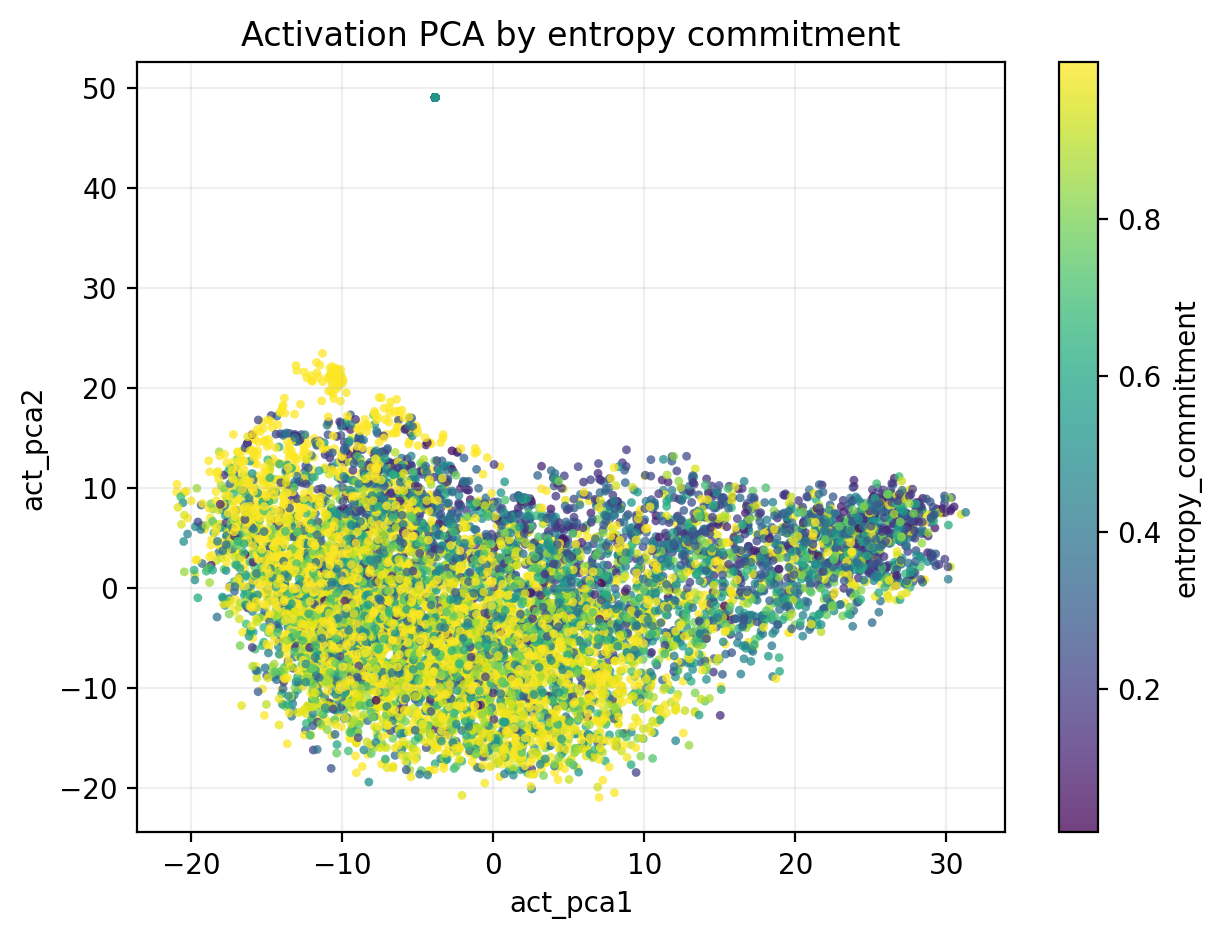

**Activation PCA colored by reasoning progress**  \
Axes: x = act_pca1; y = act_pca2  \
Color: continuous `progress` from early to late CoT prefixes  \
Saved copy: `figures/activation/report/05_activation_manifold__pca_by_progress.png`

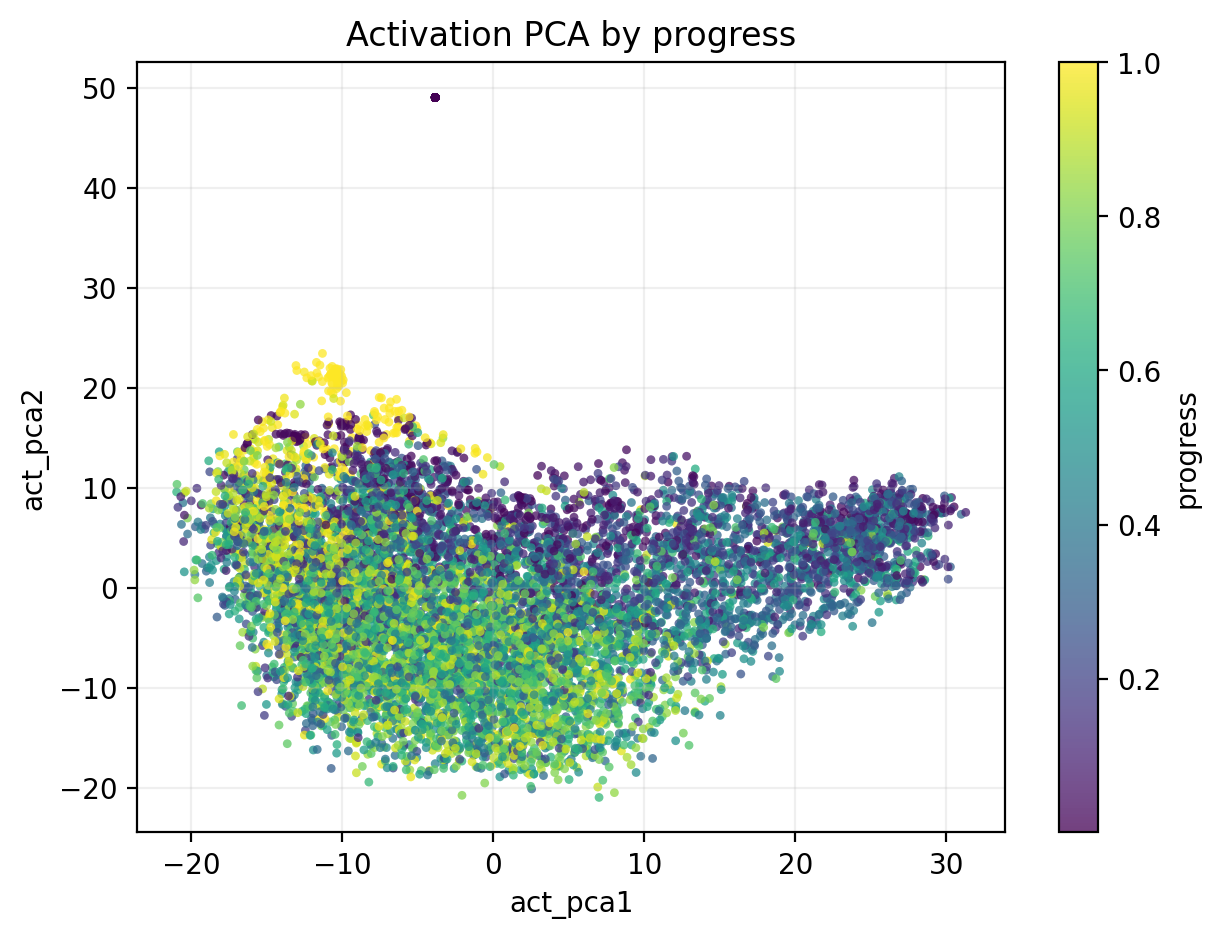

**Strict pre-action activation PCA by final action**  \
Axes: x = act_pca1; y = act_pca2  \
Color: final `agent_action`, restricted to prefixes before any explicit action mention  \
Saved copy: `figures/activation/report/05_activation_manifold__pca_strict_before_any_action_mention_by_agent_action.png`

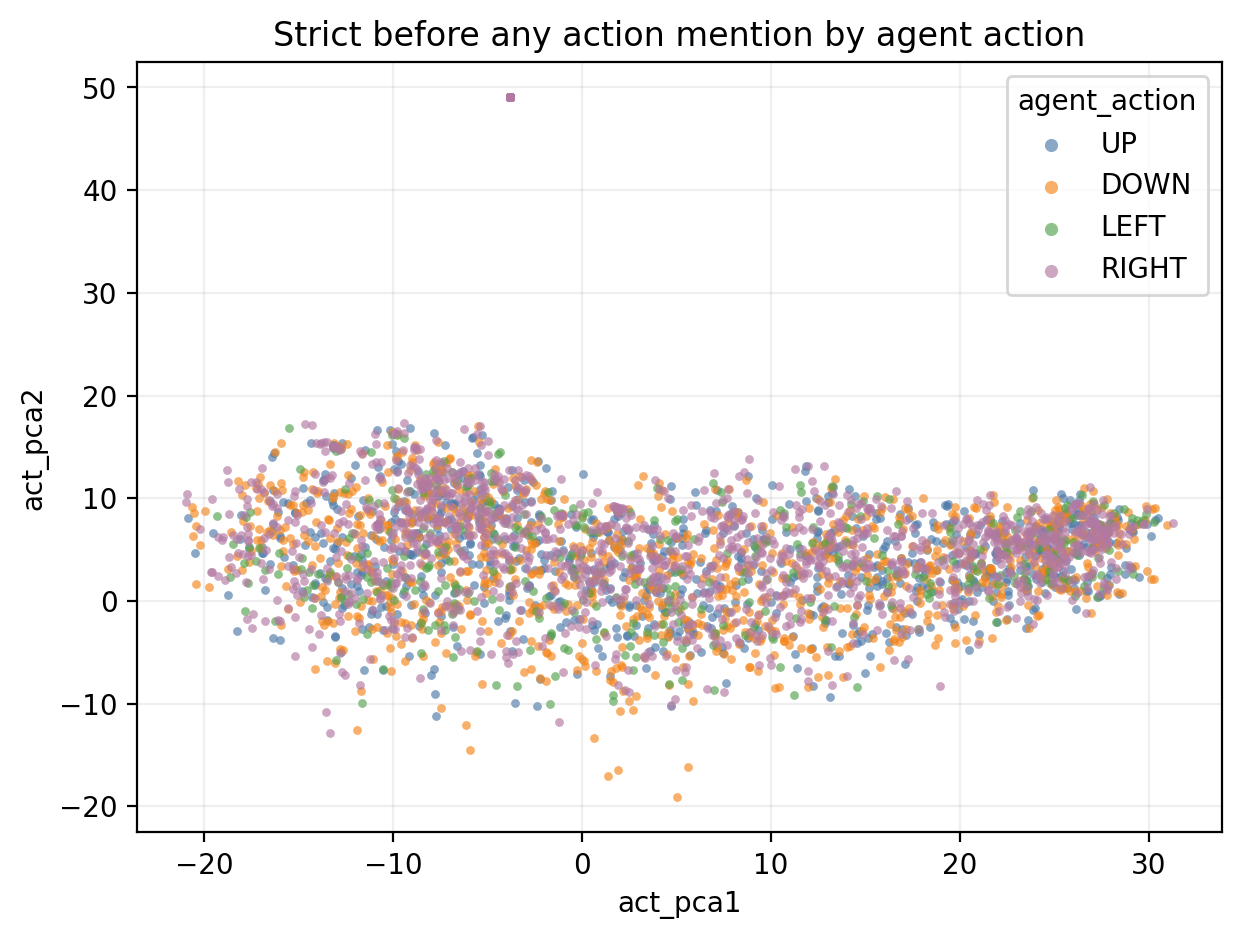

**Example activation trajectories in PCA space**  \
Axes: x = act_pca1; y = act_pca2  \
Color: trajectory color/markers identify selected decisions, with start/end markers where plotted  \
Saved copy: `figures/activation/report/05_activation_manifold__example_activation_trajectories.png`

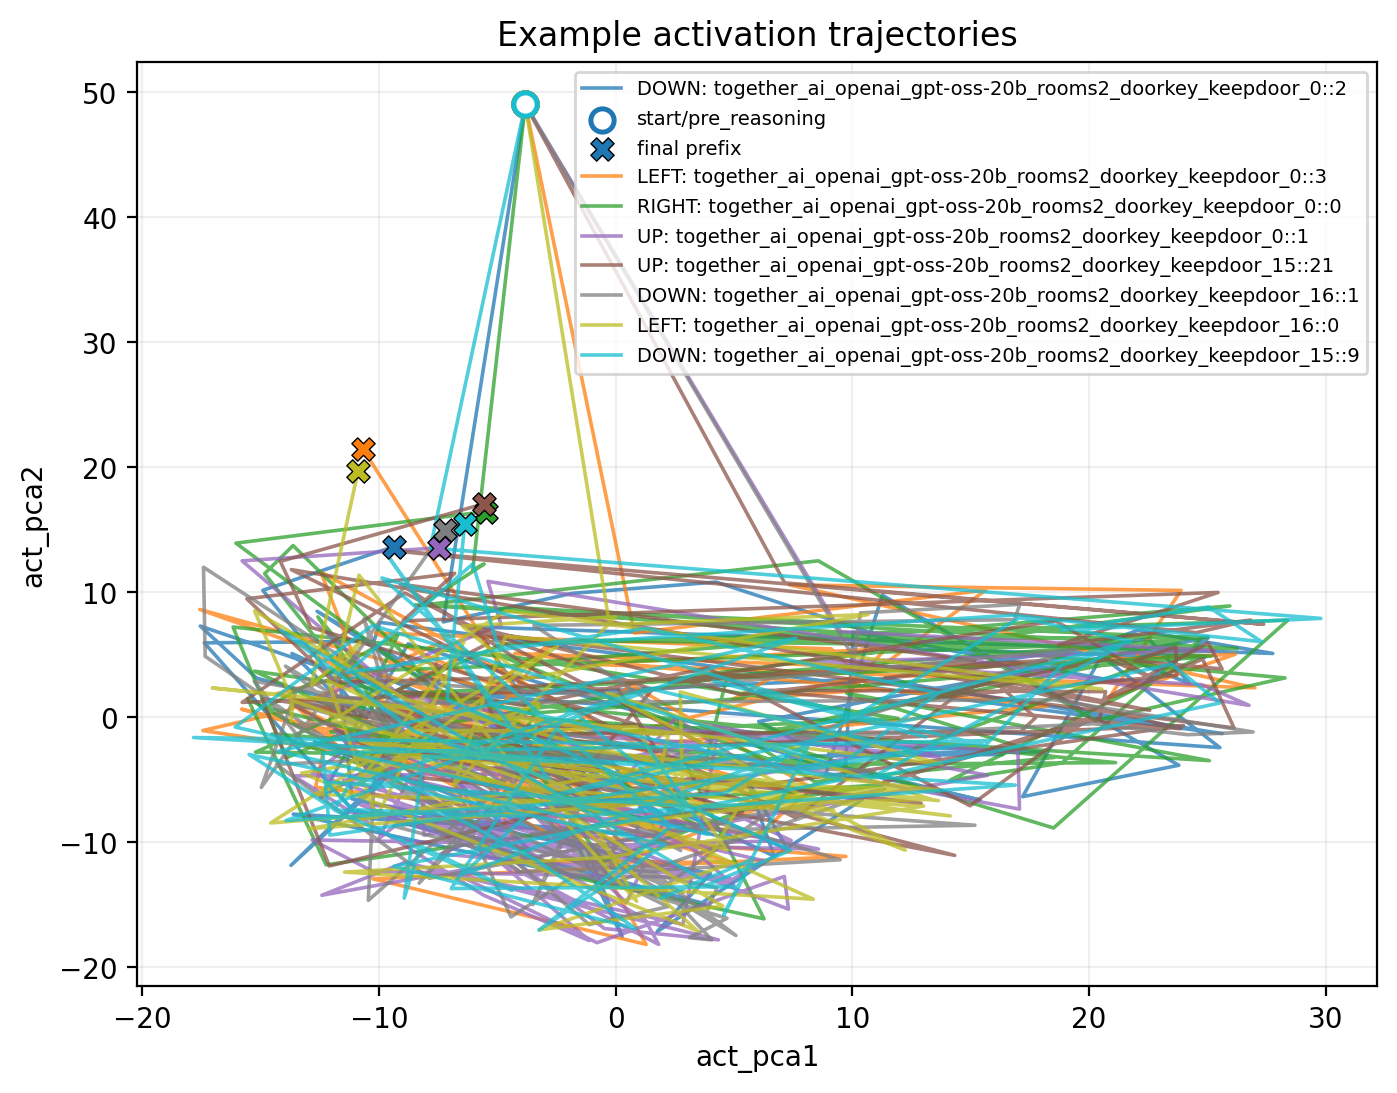

In [6]:
activation_manifold = read_table("outputs/activation/activation_manifold.parquet")
if activation_manifold is not None:
    selected_layers = sorted(pd.Series(activation_manifold.get("layer", pd.Series(dtype=float))).dropna().unique().tolist())
    selected_reps = sorted(pd.Series(activation_manifold.get("representation", pd.Series(dtype=object))).dropna().astype(str).unique().tolist())
    SUMMARY["activation_manifold"] = {"rows": len(activation_manifold), "layers": selected_layers, "representations": selected_reps}
    display(pd.DataFrame([SUMMARY["activation_manifold"]]).T.rename(columns={0: "value"}))
    display(numeric_summary(activation_manifold, ["act_pca1", "act_pca2", "commitment_to_final", "entropy_commitment", "progress"]))

for fig, caption, color in [
    ("figures/activation/manifolds/pca_by_agent_action.png", "Activation PCA colored by final agent action", "final `agent_action`"),
    ("figures/activation/manifolds/pca_by_commitment_to_final.png", "Activation PCA colored by behavior commitment to final action", "continuous `commitment_to_final`; darker/brighter values indicate higher commitment depending on the colormap"),
    ("figures/activation/manifolds/pca_by_entropy_commitment.png", "Activation PCA colored by entropy commitment", "continuous `entropy_commitment`; higher values mean lower entropy / sharper action distribution"),
    ("figures/activation/manifolds/pca_by_progress.png", "Activation PCA colored by reasoning progress", "continuous `progress` from early to late CoT prefixes"),
    ("figures/activation/manifolds/pca_strict_before_any_action_mention_by_agent_action.png", "Strict pre-action activation PCA by final action", "final `agent_action`, restricted to prefixes before any explicit action mention"),
    ("figures/activation/manifolds/example_activation_trajectories.png", "Example activation trajectories in PCA space", "trajectory color/markers identify selected decisions, with start/end markers where plotted"),
]:
    copy_and_show_figure("05_activation_manifold", fig, caption, "x = act_pca1; y = act_pca2", color)


## 6. Activation-behavior alignment

This section asks whether activation geometry predicts or aligns with behavior-side q-distribution geometry. The true-vs-predicted plot compares observed `commitment_to_final` with commitment predicted from activation features. The CCA/PLS plots show low-dimensional activation-behavior shared coordinates. The PCA-alignment plot compares activation PCA coordinates with behavior PCA coordinates after a fitted alignment. The RSA plot compares pairwise activation distances with pairwise behavior distances.


Loaded `outputs/activation/activation_behavior_alignment_metrics.csv`: **20 rows x 35 columns**

,analysis,subset,layer,representation,status,skip_reason,n_rows,n_groups,n_folds,cv_method,mse,r2_mean,predicted_commitment_pearson,predicted_commitment_spearman,pred_top_action_accuracy_vs_top_action,pred_top_action_accuracy_vs_agent_action,r2_UP,pearson_UP,r2_DOWN,pearson_DOWN,r2_LEFT,pearson_LEFT,r2_RIGHT,pearson_RIGHT,latent_component_1_corr,latent_component_2_corr,n_pairs,rsa_activation_behavior_spearman,rsa_activation_progress_spearman,rsa_activation_same_action_spearman,coordinate_corr_flat,coordinate_corr_dim1,coordinate_corr_dim2,procrustes_disparity,nearest_neighbor_action_consistency
0,ridge_activation_to_behavior_clr,all,16,delta_pre,ok,NaN,9942,10,5.0,GroupKFold(5),15.081603,-0.403889,0.164906,0.150481,0.372963,0.318749,-0.547452,0.092012,-0.493514,0.126315,-0.383691,0.210680,-0.190898,0.318518,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,pls_activation_behavior,all,16,delta_pre,ok,NaN,9942,10,5.0,GroupKFold(5),11.066415,-0.021579,NaN,NaN,NaN,NaN,-0.074539,NaN,-0.054406,NaN,0.012723,NaN,0.029906,NaN,0.008182,0.019633,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,rsa_pairwise_distances,all,16,delta_pre,ok,NaN,1500,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1124250.0,0.038909,0.153942,-0.005154,NaN,NaN,NaN,NaN,NaN
3,ridge_activation_to_behavior_clr,strict_before_any_action_mention,16,delta_pre,ok,NaN,3729,10,5.0,GroupKFold(5),16.355866,-3.419894,0.276840,0.256976,0.423438,0.333333,-3.579983,0.063454,-3.823850,0.116563,-3.291189,0.183868,-2.984556,0.189773,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,pls_activation_behavior,strict_before_any_action_mention,16,delta_pre,ok,NaN,3729,10,5.0,GroupKFold(5),4.005915,-0.063873,NaN,NaN,NaN,NaN,-0.215413,NaN,-0.115894,NaN,0.132344,NaN,-0.056529,NaN,0.103810,-0.022043,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,count,mean,std,min,25%,50%,75%,max
mse,10.0,13.18918,10.038374,3.329364,5.084543,13.074009,16.153053,37.13493


**True vs predicted behavioral commitment from activations**  \
Axes: x = true commitment_to_final; y = predicted commitment_to_final  \
Color: point color, if present, identifies action or density  \
Saved copy: `figures/activation/report/06_activation_behavior_alignment__predicted_vs_true_commitment.png`

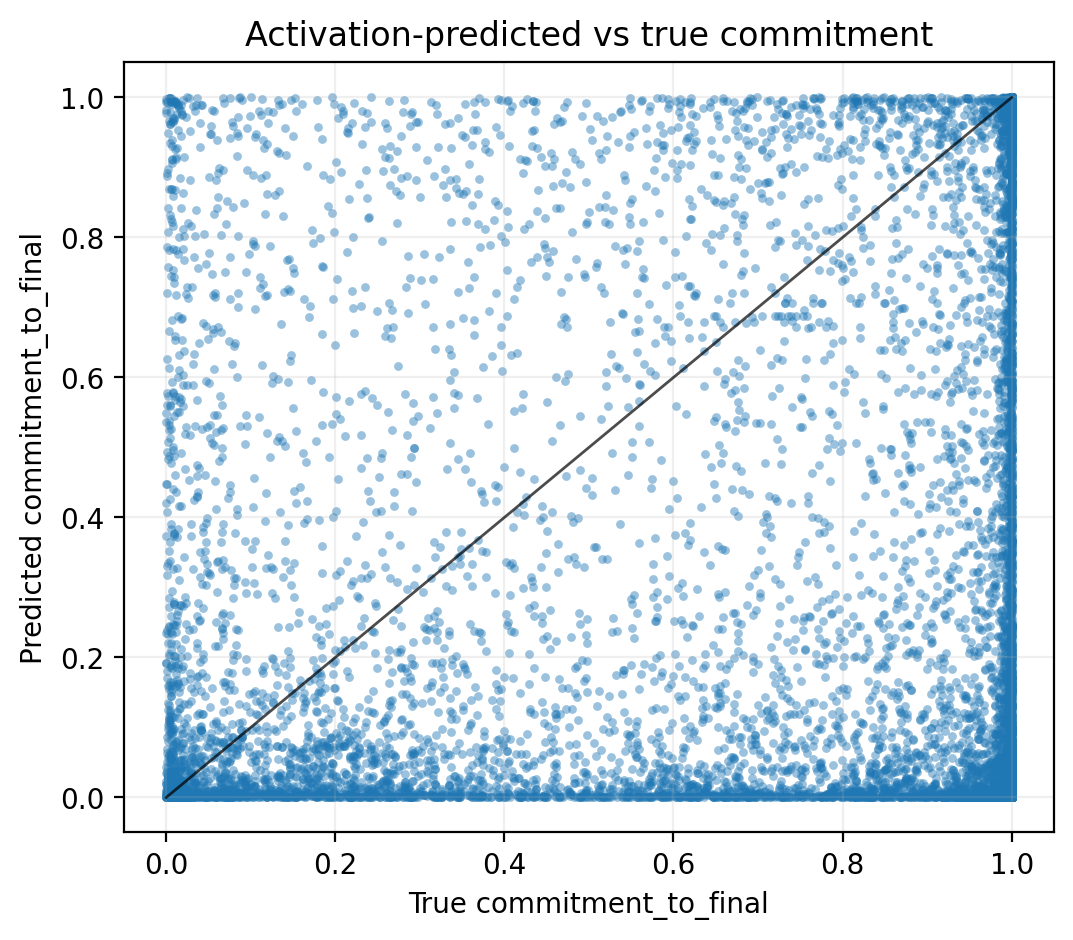

**CCA/PLS activation-behavior embedding by final action**  \
Axes: x = first CCA/PLS coordinate; y = second CCA/PLS coordinate  \
Color: final `agent_action`  \
Saved copy: `figures/activation/report/06_activation_behavior_alignment__cca_by_agent_action.png`

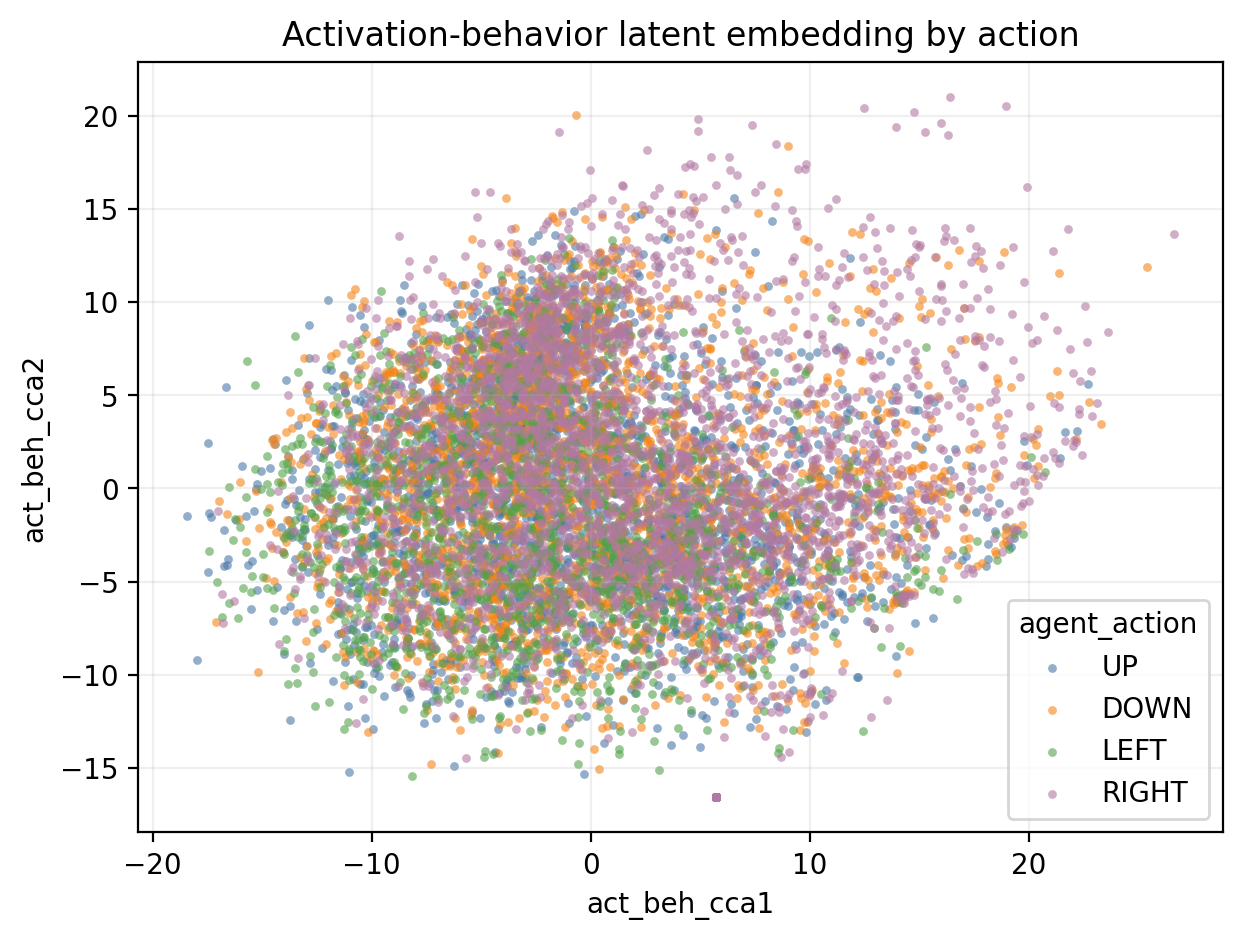

**Behavior PCA vs aligned activation PCA**  \
Axes: x/y compare behavior PCA coordinates with linearly aligned activation PCA coordinates  \
Color: point color, if present, identifies action or split  \
Saved copy: `figures/activation/report/06_activation_behavior_alignment__behavior_vs_activation_pca_alignment.png`

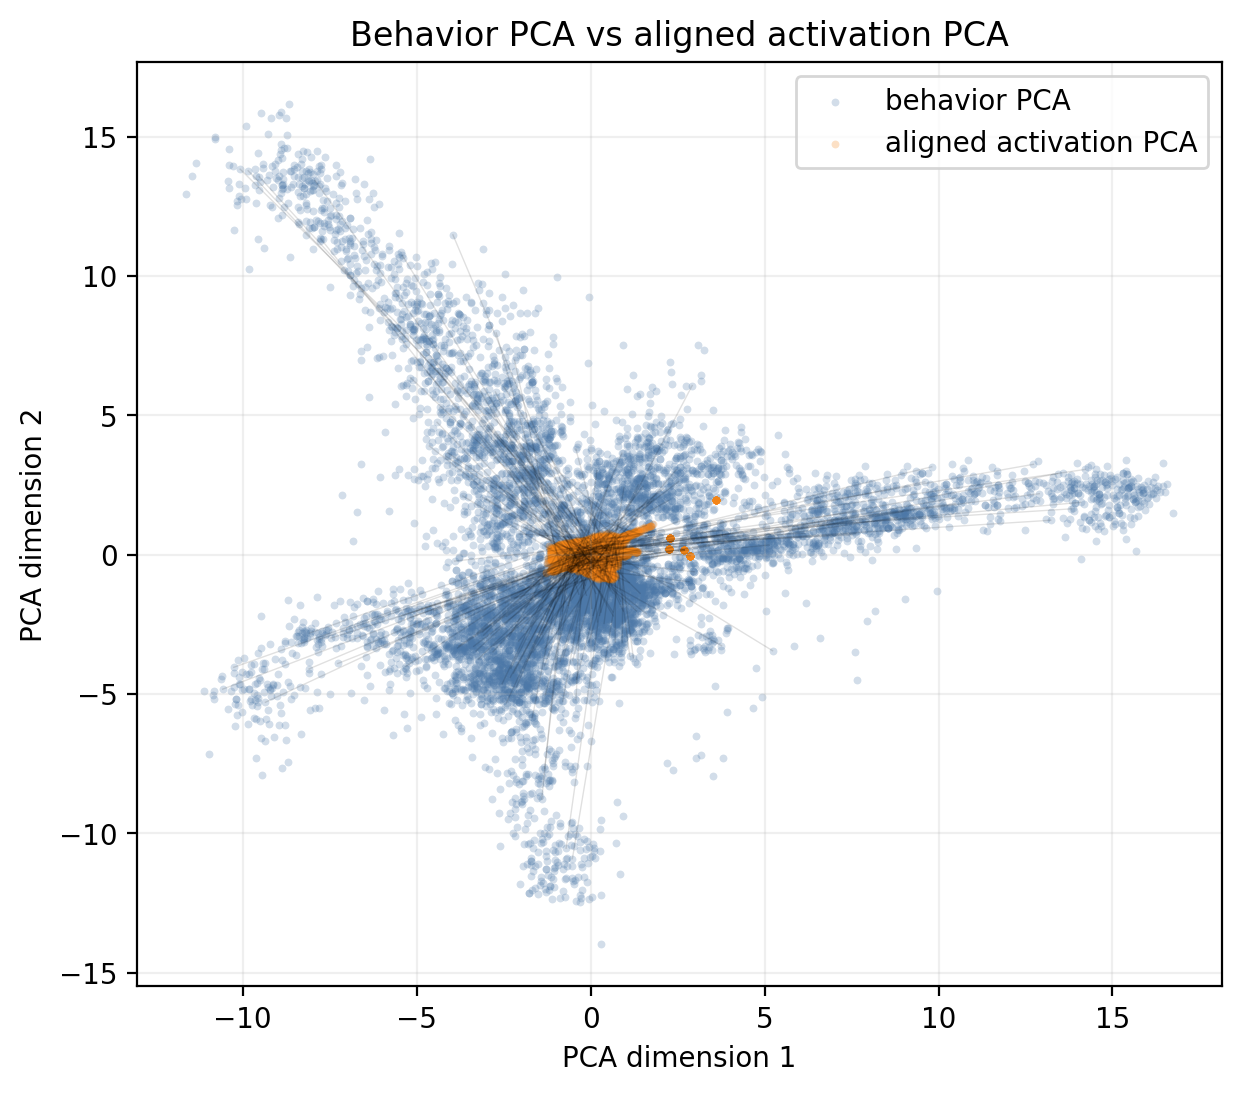

**Representational similarity: activation vs behavior distance**  \
Axes: x = pairwise activation distance; y = pairwise behavior CLR distance  \
Color: point color, if present, identifies progress/action relation  \
Saved copy: `figures/activation/report/06_activation_behavior_alignment__rsa_activation_vs_behavior_distance.png`

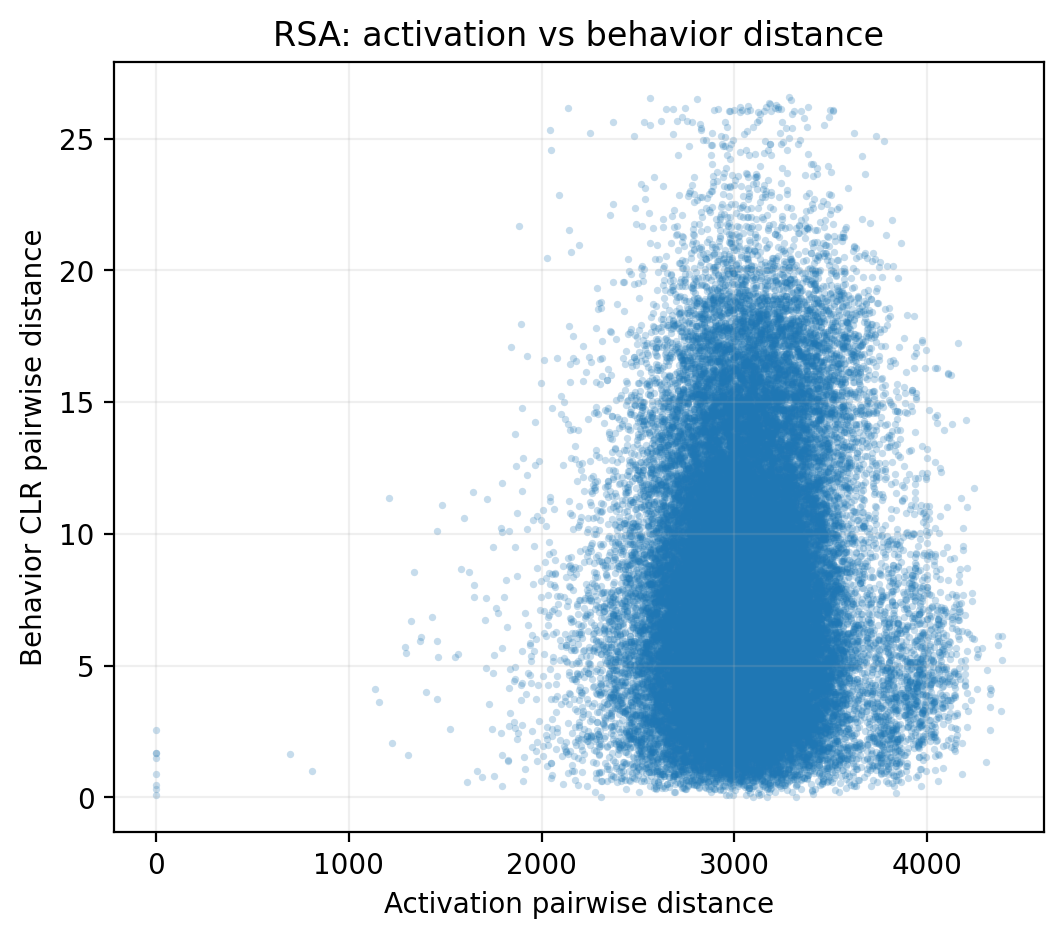

In [7]:
activation_behavior_alignment_metrics = read_table("outputs/activation/activation_behavior_alignment_metrics.csv")
if activation_behavior_alignment_metrics is not None:
    display(activation_behavior_alignment_metrics.head())
    display(numeric_summary(activation_behavior_alignment_metrics, ["r2", "mean_r2", "mse", "pearson", "spearman", "accuracy", "balanced_accuracy"]))
    SUMMARY["alignment_rows"] = len(activation_behavior_alignment_metrics)

for fig, caption, axis, color in [
    ("figures/activation/alignment/predicted_vs_true_commitment.png", "True vs predicted behavioral commitment from activations", "x = true commitment_to_final; y = predicted commitment_to_final", "point color, if present, identifies action or density"),
    ("figures/activation/alignment/cca_by_agent_action.png", "CCA/PLS activation-behavior embedding by final action", "x = first CCA/PLS coordinate; y = second CCA/PLS coordinate", "final `agent_action`"),
    ("figures/activation/alignment/behavior_vs_activation_pca_alignment.png", "Behavior PCA vs aligned activation PCA", "x/y compare behavior PCA coordinates with linearly aligned activation PCA coordinates", "point color, if present, identifies action or split"),
    ("figures/activation/alignment/rsa_activation_vs_behavior_distance.png", "Representational similarity: activation vs behavior distance", "x = pairwise activation distance; y = pairwise behavior CLR distance", "point color, if present, identifies progress/action relation"),
]:
    copy_and_show_figure("06_activation_behavior_alignment", fig, caption, axis, color)


## 7. Action centroids and activation basins

Action centroids are built in activation space from high-commitment examples for each final action. For each prefix activation, the activation basin is the action whose centroid has the highest similarity. Activation lock-in is the point where the basin matches the final action with sufficient margin for a sustained run of measured prefixes.


Loaded `outputs/activation/activation_centroid_scores.parquet`: **9,942 rows x 92 columns**

Loaded `outputs/activation/activation_basin_summary.parquet`: **132 rows x 26 columns**

,count,mean,std,min,25%,50%,75%,max
activation_margin,9942.0,0.002885,0.002367,0.000000,0.000998,0.002261,0.004260,0.013729
act_sim_final,9942.0,0.820999,0.101160,0.000000,0.809057,0.836889,0.857411,0.913980
activation_commitment_to_final,9942.0,0.820999,0.101160,0.000000,0.809057,0.836889,0.857411,0.913980
progress,9942.0,0.501765,0.292822,0.000167,0.248578,0.504931,0.758342,1.000000


,decision_id,trajectory_id,step_id,agent_action,num_prefixes,final_prefix_progress,final_activation_basin_action,final_activation_basin_matches_final,final_activation_margin,final_act_sim_final,mean_act_sim_final,mean_activation_basin_matches_final,first_activation_basin_lock_progress,permanent_activation_basin_lock_progress,activation_switch_count,first_behavior_lock_in_progress,behavior_switch_count,first_behavior_lock_in_progress_from_permanent_summary,permanent_behavior_lock_progress,behavior_switch_count_from_permanent_summary,activation_minus_behavior_permanent_lock_progress,activation_minus_behavior_first_lock_progress,layer,representation,centroid_source,lock_margin_threshold
0,together_ai_openai_gpt-oss-20b_rooms2_doorkey_keepdoor_0::0,together_ai_openai_gpt-oss-20b_rooms2_doorkey_keepdoor_0,0,RIGHT,80,1.0,RIGHT,True,0.005674,0.680804,0.814923,0.4875,0.01304,0.991035,35,0.000815,4,0.000815,0.294214,4,0.696822,0.012225,16,delta_pre,high_commitment_prefixes,0.005
1,together_ai_openai_gpt-oss-20b_rooms2_doorkey_keepdoor_0::1,together_ai_openai_gpt-oss-20b_rooms2_doorkey_keepdoor_0,1,UP,80,1.0,UP,True,0.000243,0.723992,0.836413,0.0500,NaN,NaN,26,0.329793,9,0.329793,0.329793,9,NaN,NaN,16,delta_pre,high_commitment_prefixes,0.005
2,together_ai_openai_gpt-oss-20b_rooms2_doorkey_keepdoor_0::2,together_ai_openai_gpt-oss-20b_rooms2_doorkey_keepdoor_0,2,DOWN,80,1.0,RIGHT,False,0.004401,0.744426,0.820241,0.3875,NaN,NaN,45,0.267148,8,0.267148,0.583032,8,NaN,NaN,16,delta_pre,high_commitment_prefixes,0.005
3,together_ai_openai_gpt-oss-20b_rooms2_doorkey_keepdoor_0::3,together_ai_openai_gpt-oss-20b_rooms2_doorkey_keepdoor_0,3,LEFT,80,1.0,RIGHT,False,0.009463,0.700366,0.822899,0.3000,NaN,NaN,50,0.533512,6,0.533512,0.533512,6,NaN,NaN,16,delta_pre,high_commitment_prefixes,0.005
4,together_ai_openai_gpt-oss-20b_rooms2_doorkey_keepdoor_0::4,together_ai_openai_gpt-oss-20b_rooms2_doorkey_keepdoor_0,4,DOWN,80,1.0,RIGHT,False,0.009987,0.716486,0.808374,0.4000,NaN,NaN,34,0.688742,5,0.688742,0.688742,5,NaN,NaN,16,delta_pre,high_commitment_prefixes,0.005


,count,mean,std,min,25%,50%,75%,max
first_activation_basin_lock_progress,36.0,0.308882,0.314599,0.010753,0.046091,0.189348,0.517375,0.97584
permanent_activation_basin_lock_progress,25.0,0.935371,0.147384,0.342857,0.971098,0.991035,1.000000,1.00000
activation_switch_count,132.0,32.250000,11.446774,3.000000,25.500000,35.000000,41.000000,53.00000


**Similarity to final-action centroid over progress**  \
Axes: x = reasoning progress bin; y = mean similarity to final-action centroid  \
Color: line/color may separate subsets or actions  \
Saved copy: `figures/activation/report/07_action_centroids__activation_similarity_to_final_centroid_over_progress.png`

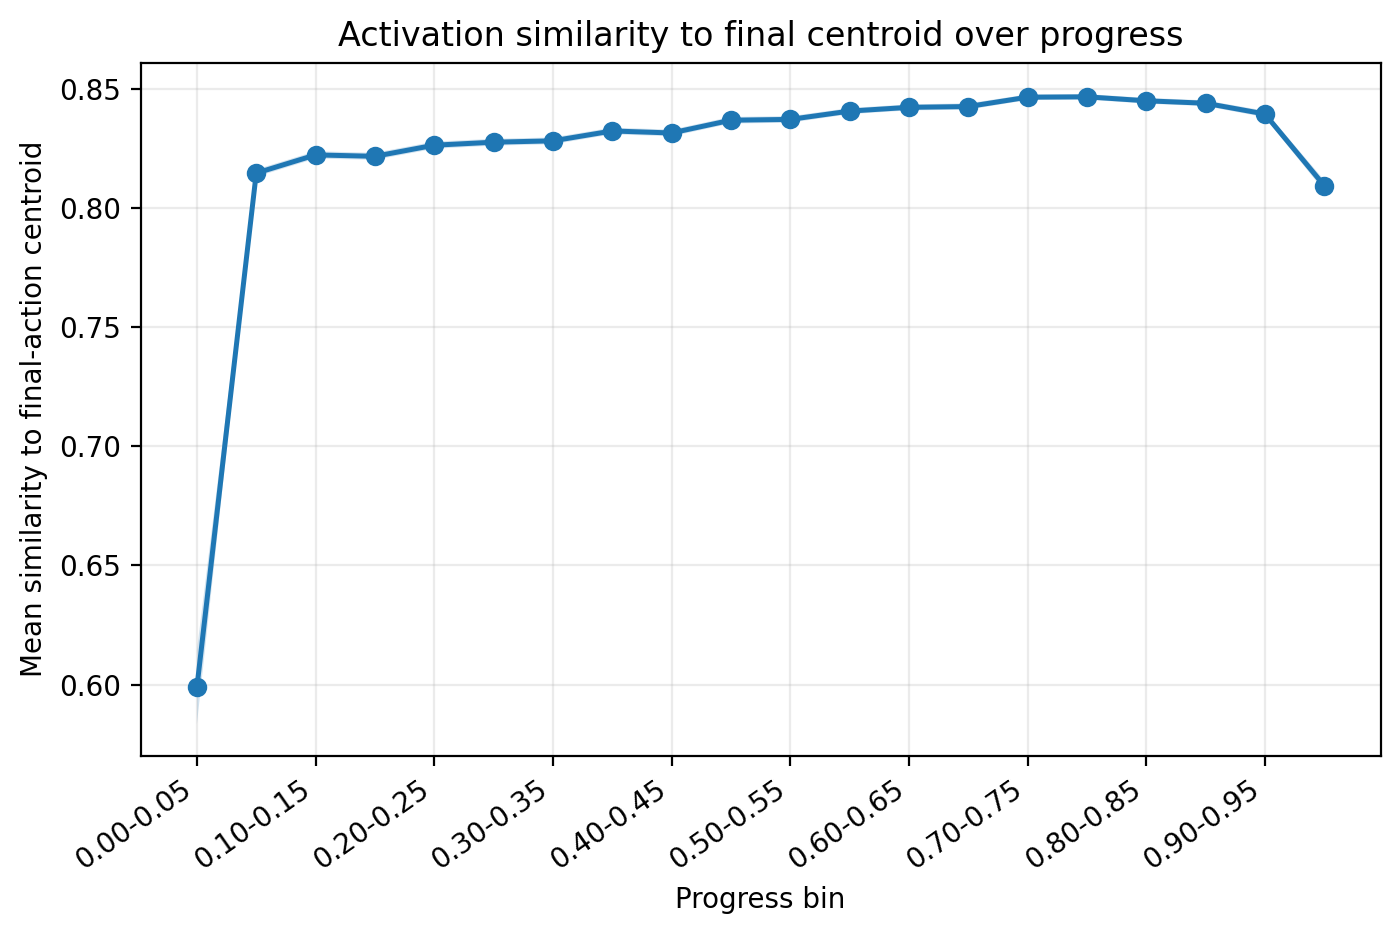

**Activation basin accuracy over progress**  \
Axes: x = reasoning progress bin; y = fraction of prefixes whose activation basin matches final action  \
Color: line/color may separate subsets  \
Saved copy: `figures/activation/report/07_action_centroids__activation_basin_accuracy_over_progress.png`

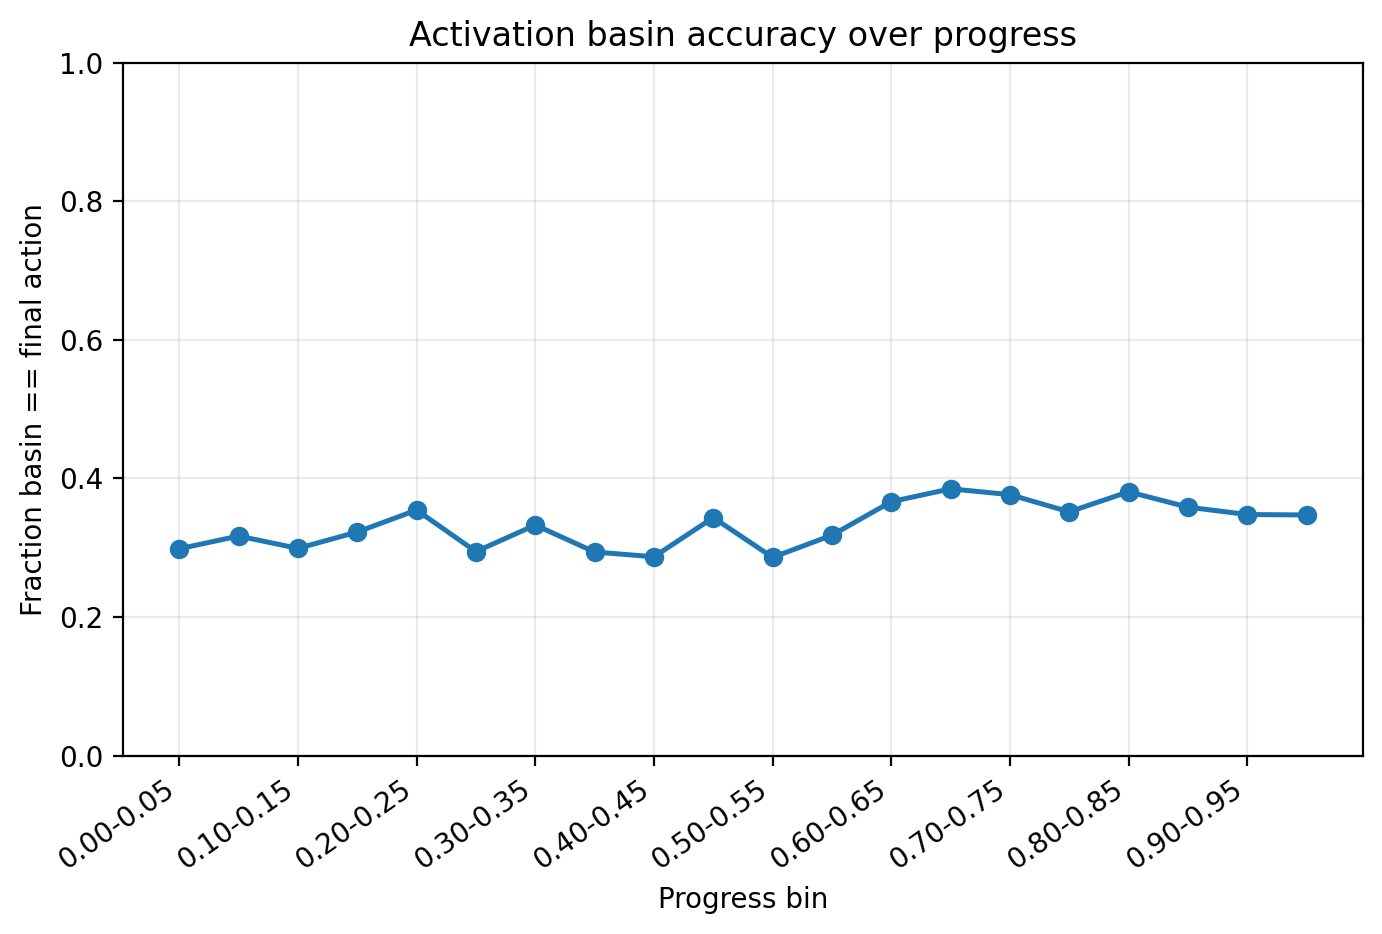

**Behavior vs activation permanent lock-in**  \
Axes: x = behavior permanent lock-in progress; y = activation permanent basin lock-in progress  \
Color: point color, if present, identifies final action  \
Saved copy: `figures/activation/report/07_action_centroids__behavior_vs_activation_permanent_lockin.png`

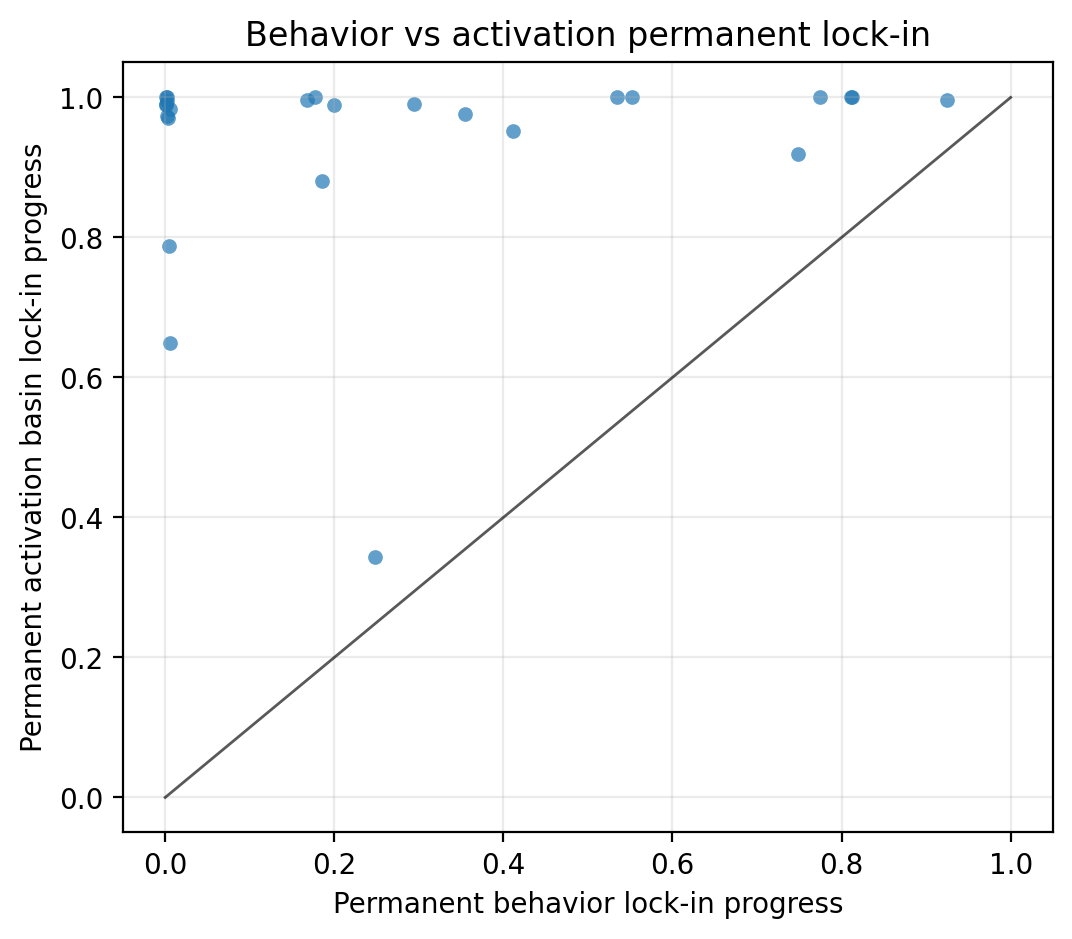

**Example activation basin trajectories**  \
Axes: x = prefix token index; y = centroid similarity or basin-related score  \
Color: line color identifies action centroid  \
Saved copy: `figures/activation/report/07_action_centroids__example_activation_basin_trajectories.png`

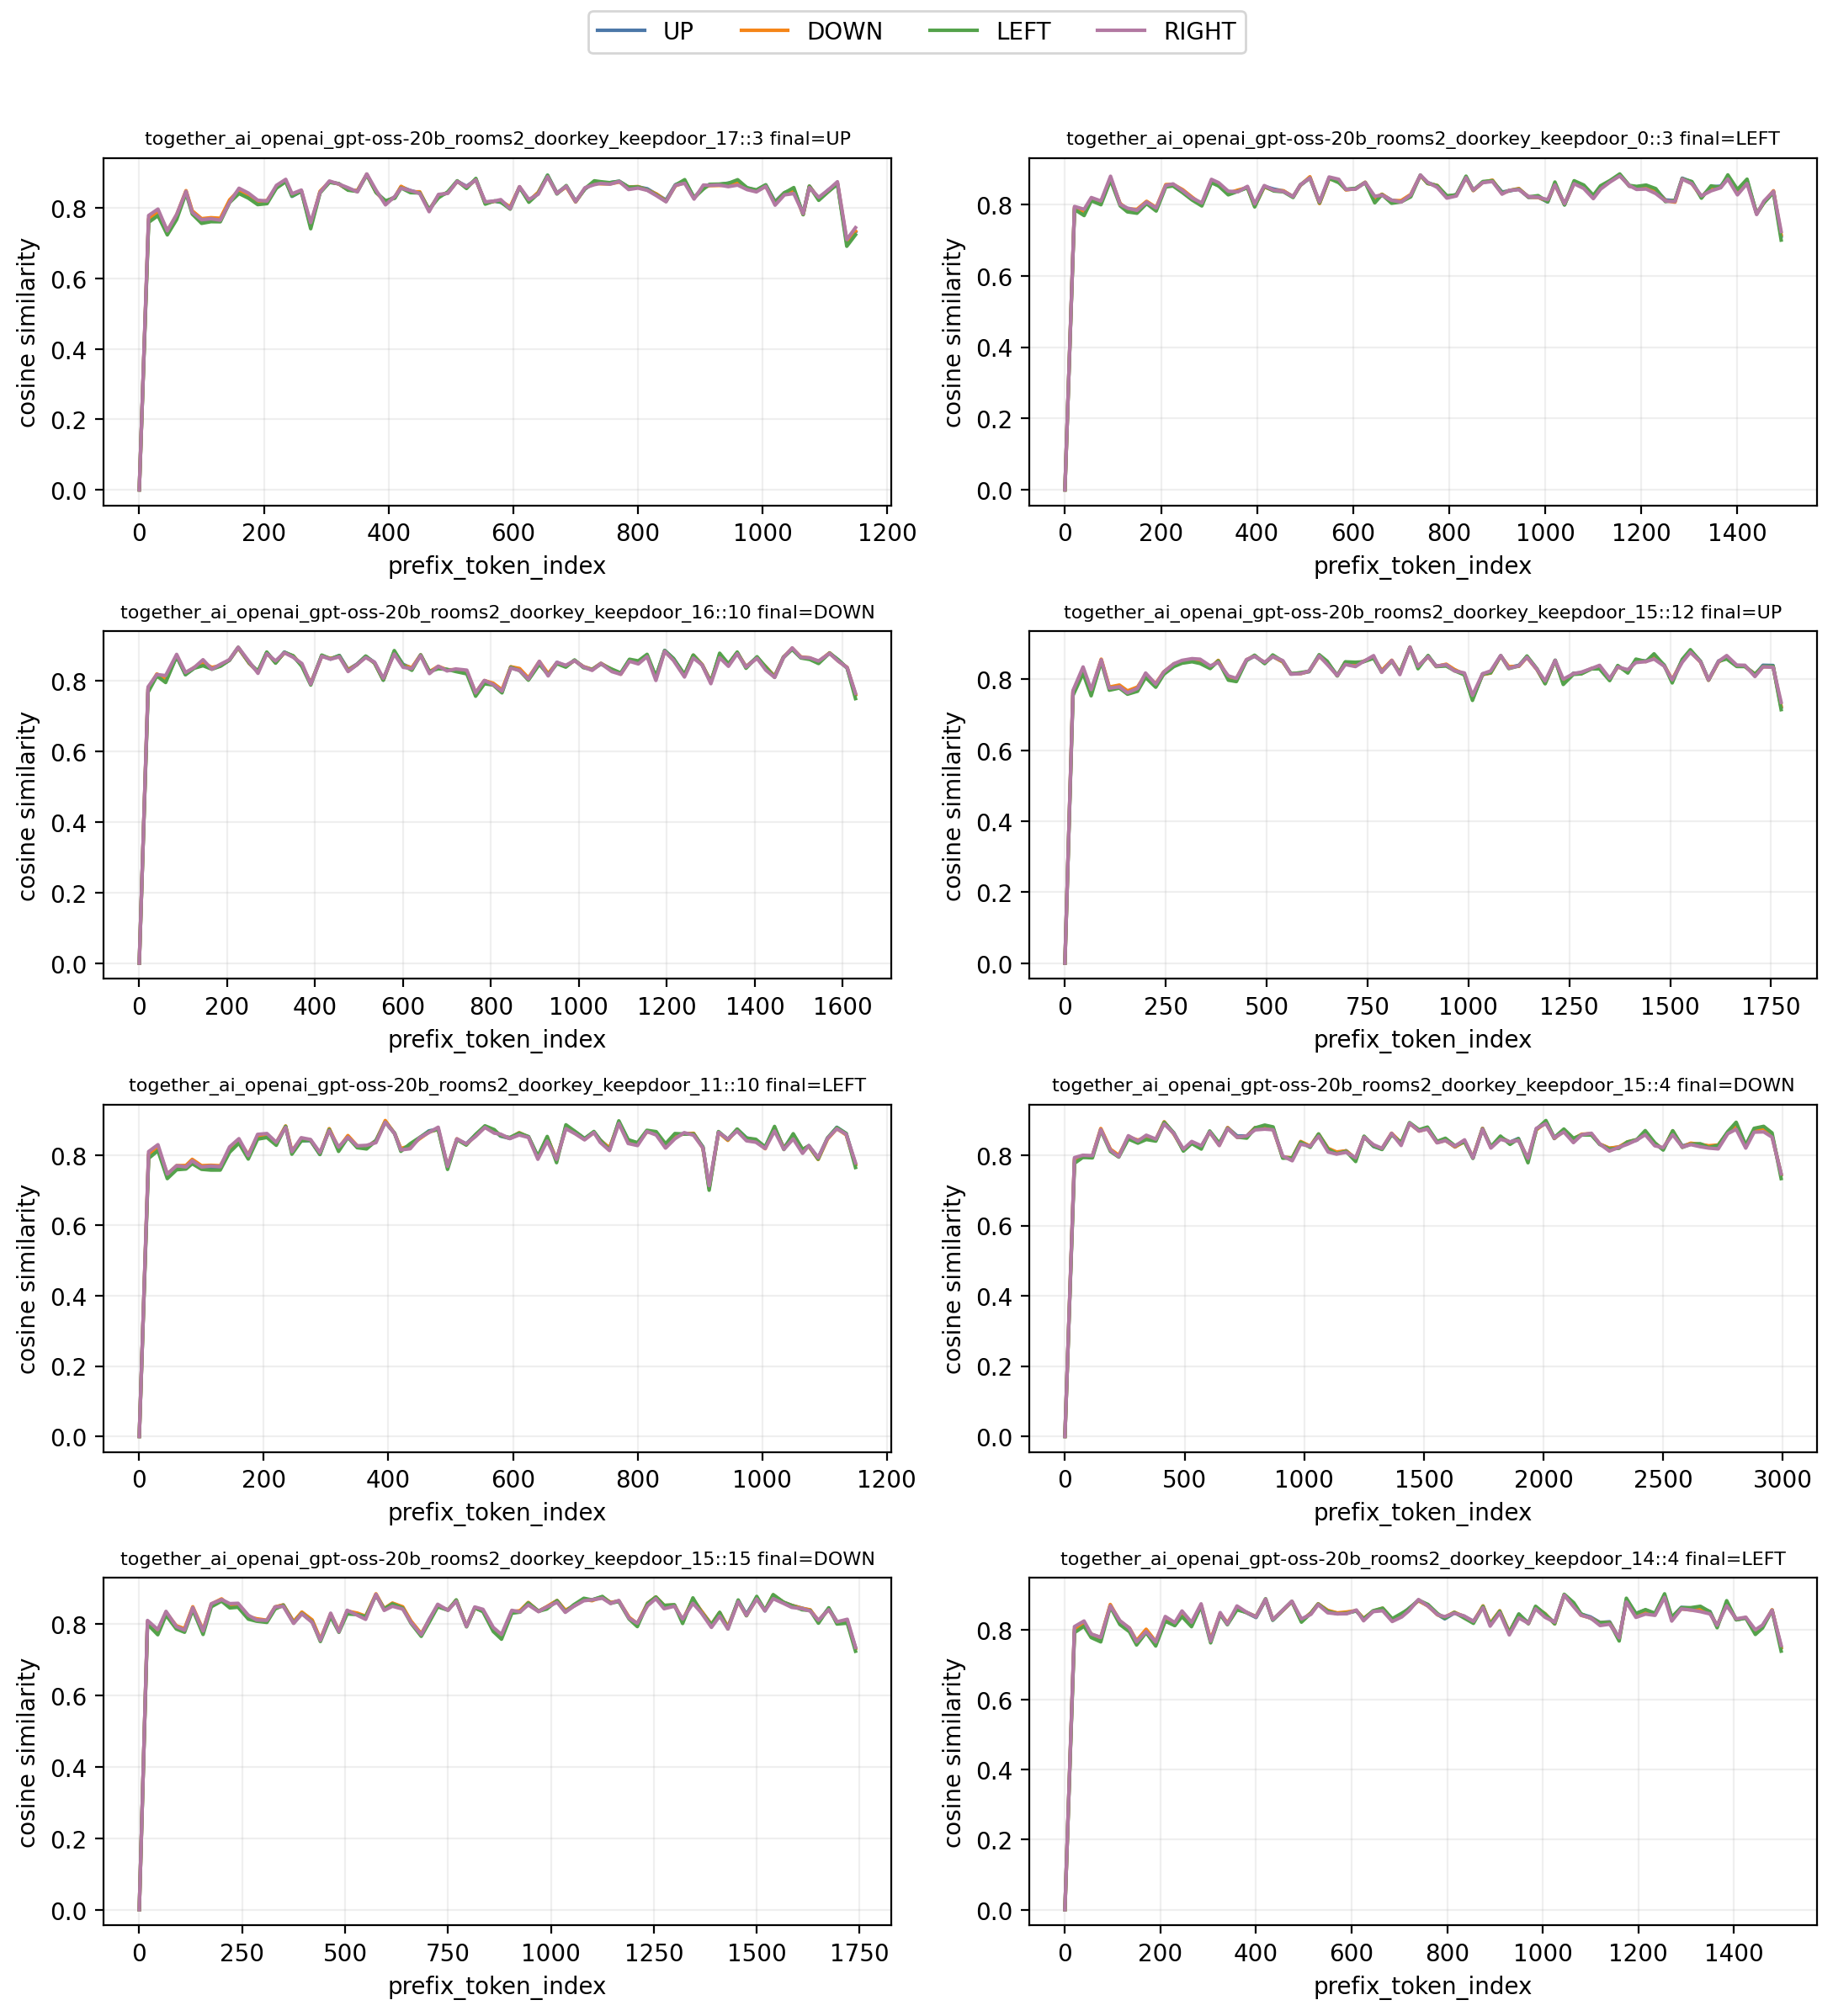

In [8]:
activation_centroid_scores = read_table("outputs/activation/activation_centroid_scores.parquet")
activation_basin_summary = read_table("outputs/activation/activation_basin_summary.parquet")
if activation_centroid_scores is not None:
    display(numeric_summary(activation_centroid_scores, ["activation_margin", "act_sim_final", "activation_commitment_to_final", "progress"]))
    if "activation_basin_matches_final" in activation_centroid_scores.columns:
        SUMMARY["activation_basin_accuracy"] = float(activation_centroid_scores["activation_basin_matches_final"].astype(float).mean())
if activation_basin_summary is not None:
    display(activation_basin_summary.head())
    display(numeric_summary(activation_basin_summary, ["first_activation_basin_lock_progress", "permanent_activation_basin_lock_progress", "activation_switch_count"]))

for fig, caption, axis, color in [
    ("figures/activation/centroids/activation_similarity_to_final_centroid_over_progress.png", "Similarity to final-action centroid over progress", "x = reasoning progress bin; y = mean similarity to final-action centroid", "line/color may separate subsets or actions"),
    ("figures/activation/centroids/activation_basin_accuracy_over_progress.png", "Activation basin accuracy over progress", "x = reasoning progress bin; y = fraction of prefixes whose activation basin matches final action", "line/color may separate subsets"),
    ("figures/activation/centroids/behavior_vs_activation_permanent_lockin.png", "Behavior vs activation permanent lock-in", "x = behavior permanent lock-in progress; y = activation permanent basin lock-in progress", "point color, if present, identifies final action"),
    ("figures/activation/centroids/example_activation_basin_trajectories.png", "Example activation basin trajectories", "x = prefix token index; y = centroid similarity or basin-related score", "line color identifies action centroid"),
]:
    copy_and_show_figure("07_action_centroids", fig, caption, axis, color)


## 8. Pre-reasoning vs post-reasoning

This section compares the model state before reasoning (`h_pre`) and after reasoning (`h_post`). If `h_pre` predicts the final action, the prompt induces an internal action prior. If `h_post` predicts the final action more strongly, reasoning sharpens the internal action commitment. If `h_post - h_pre` predicts action, then the reasoning-induced change is action-specific.


Loaded `outputs/activation/pre_post_reasoning_features.parquet`: **1,584 rows x 53 columns**

Loaded `outputs/activation/pre_post_decoding_metrics.csv`: **60 rows x 16 columns**

,count,mean,std,min,25%,50%,75%,max
delta_post_pre_l2,1584.0,3635.245605,4983.108398,166.240646,494.984093,1283.184875,4257.713684,21257.267578
pre_post_cosine,1584.0,0.639902,0.107564,0.276900,0.572133,0.647269,0.720196,0.800061


,status,skip_reason,n_rows,n_groups,n_folds,cv_method,accuracy,balanced_accuracy,macro_f1,layer,input_state,target,model,r2,mse,pearson
0,ok,NaN,132,10,5,GroupKFold(5),0.333333,0.321530,0.311012,0,pre,agent_action,logistic_regression,NaN,NaN,NaN
1,ok,NaN,132,10,5,GroupKFold(5),0.651515,0.658381,0.656832,0,post,agent_action,logistic_regression,NaN,NaN,NaN
2,ok,NaN,132,10,5,GroupKFold(5),0.643939,0.656227,0.654237,0,delta_post_pre,agent_action,logistic_regression,NaN,NaN,NaN
3,ok,NaN,132,10,5,GroupKFold(5),NaN,NaN,NaN,0,pre,prompt_only_commitment_to_final,ridge,-0.331970,1.060279e-01,0.102233
4,ok,NaN,132,10,5,GroupKFold(5),NaN,NaN,NaN,0,post,final_prefix_commitment_to_final,ridge,-2.992243,3.244807e-12,0.011493


,count,mean,std,min,25%,50%,75%,max
balanced_accuracy,36.0,0.388746,0.094772,0.222414,0.335289,0.364504,0.432013,0.658381
accuracy,36.0,0.384470,0.091778,0.234848,0.325758,0.359848,0.433712,0.651515
macro_f1,36.0,0.384954,0.094954,0.223994,0.331140,0.358415,0.431747,0.656832
r2,24.0,-0.853457,0.557640,-2.992243,-0.994052,-0.739915,-0.509167,-0.283058
pearson,24.0,-0.015960,0.070664,-0.238597,-0.033076,0.003444,0.018074,0.102233


**Pre vs post action decoding by layer**  \
Axes: x = layer; y = balanced action decoding accuracy  \
Color: line color distinguishes pre, post, and post-minus-pre representations  \
Saved copy: `figures/activation/report/08_pre_post__pre_vs_post_action_decoding_by_layer.png`

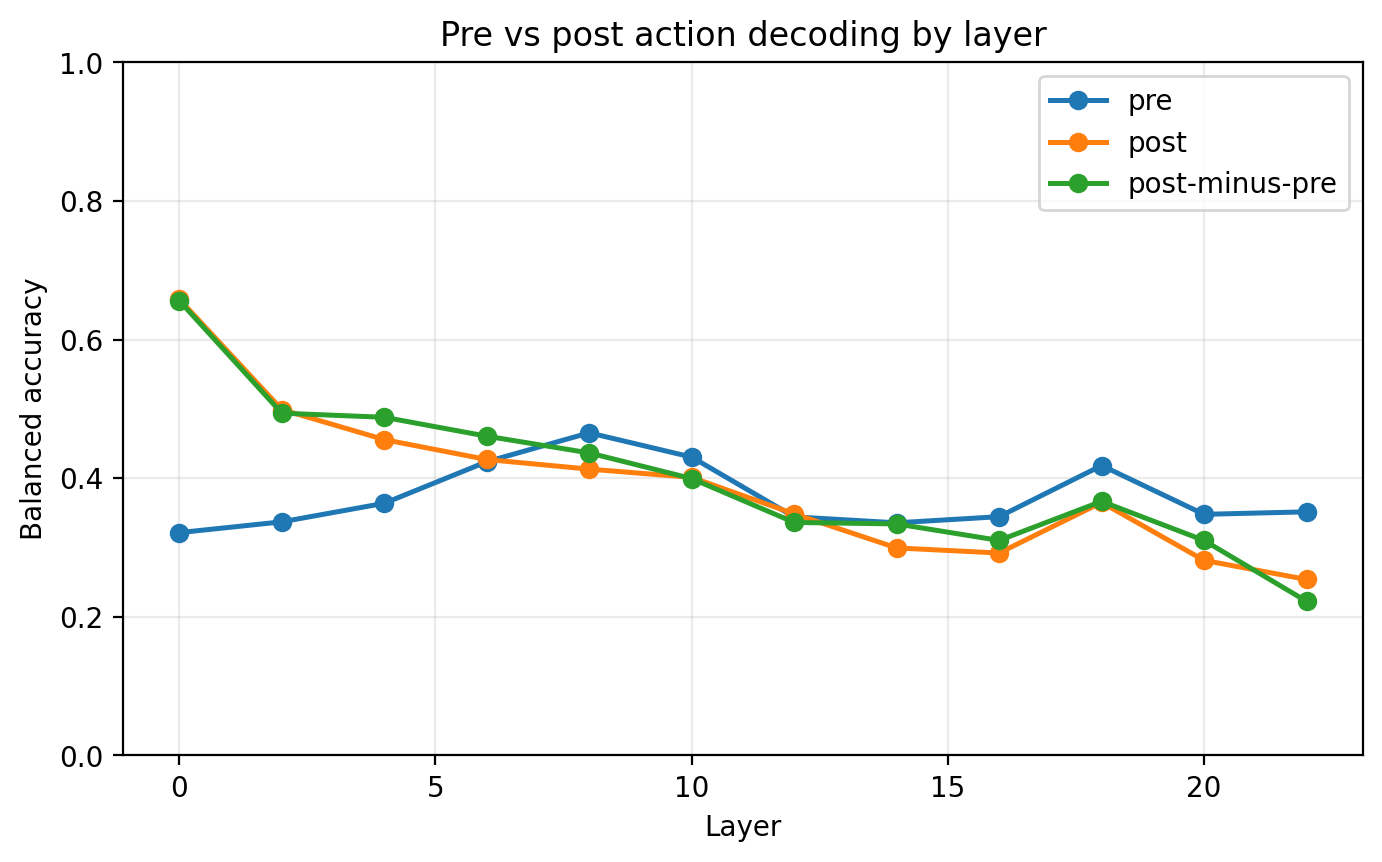

**Post-minus-pre norm by final action**  \
Axes: x = final agent action; y = ||h_post - h_pre||  \
Color: bar/point color identifies final action  \
Saved copy: `figures/activation/report/08_pre_post__post_minus_pre_norm_by_action.png`

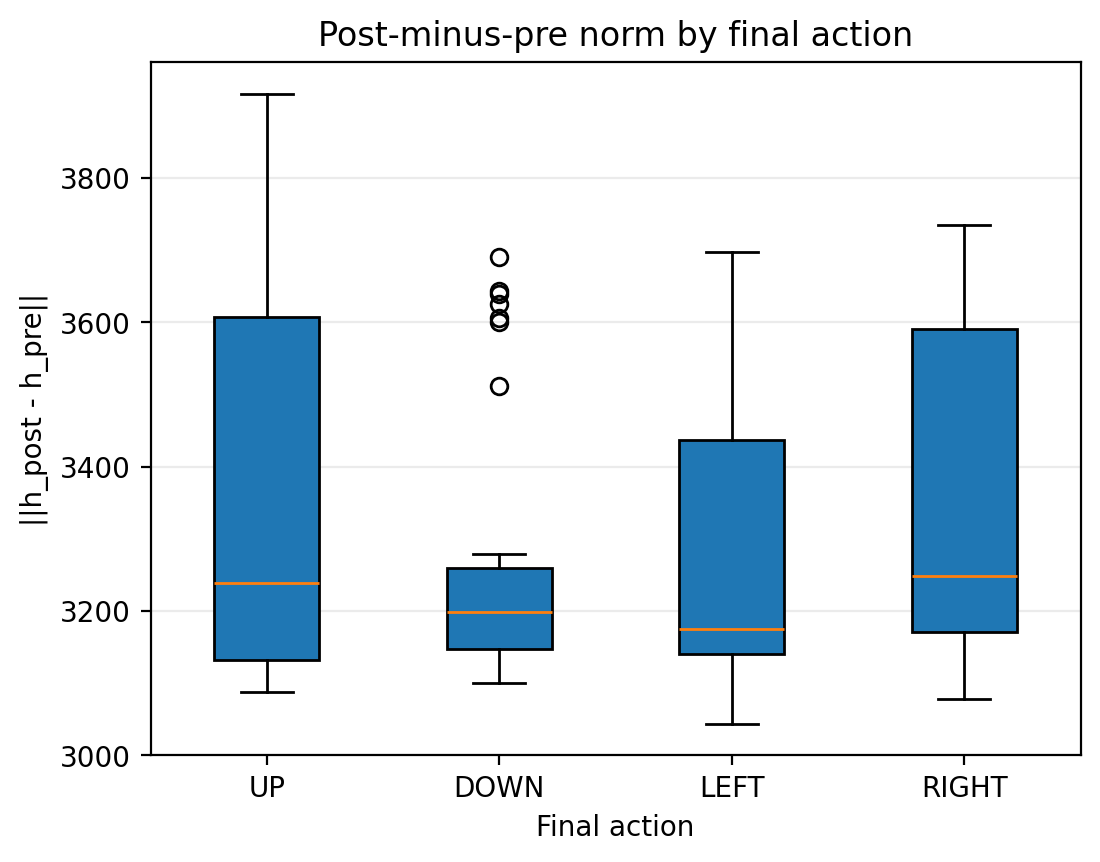

**PCA trajectories from pre to post states**  \
Axes: x = first PCA component; y = second PCA component for pre/post states  \
Color: color identifies final agent action; line connects pre to post for a decision  \
Saved copy: `figures/activation/report/08_pre_post__pre_post_pca_trajectories.png`

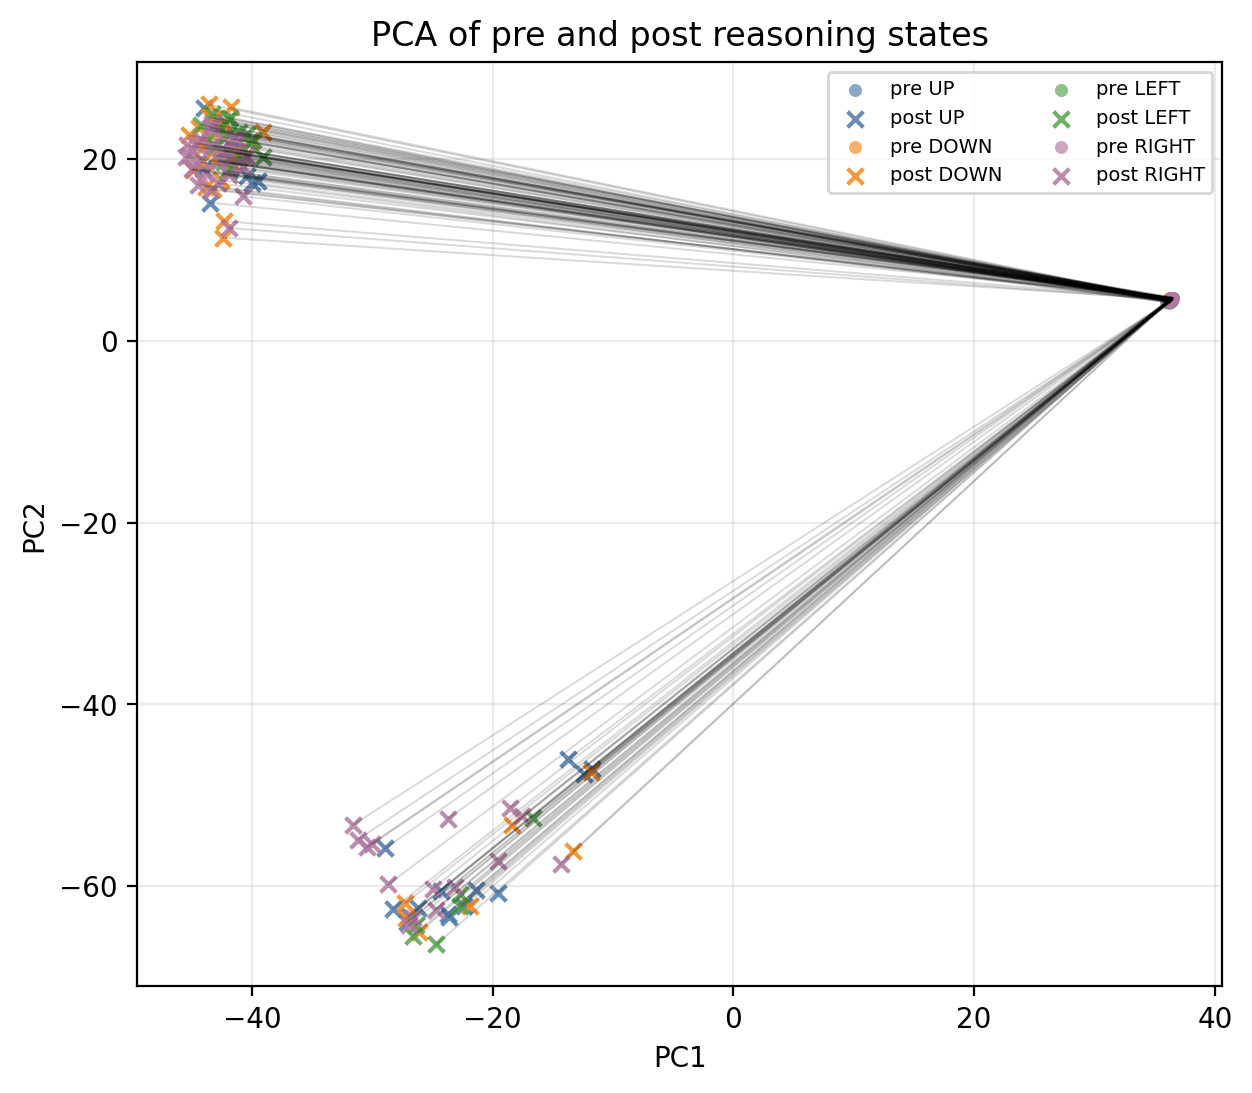

In [9]:
pre_post_features = read_table("outputs/activation/pre_post_reasoning_features.parquet")
pre_post_metrics = read_table("outputs/activation/pre_post_decoding_metrics.csv")
if pre_post_features is not None:
    display(numeric_summary(pre_post_features, ["delta_post_pre_l2", "pre_post_cosine", "pre_final_centroid_similarity", "post_final_centroid_similarity"]))
if pre_post_metrics is not None:
    display(pre_post_metrics.head())
    display(numeric_summary(pre_post_metrics, ["balanced_accuracy", "accuracy", "macro_f1", "r2", "pearson"]))

for fig, caption, axis, color in [
    ("figures/activation/pre_post/pre_vs_post_action_decoding_by_layer.png", "Pre vs post action decoding by layer", "x = layer; y = balanced action decoding accuracy", "line color distinguishes pre, post, and post-minus-pre representations"),
    ("figures/activation/pre_post/post_minus_pre_norm_by_action.png", "Post-minus-pre norm by final action", "x = final agent action; y = ||h_post - h_pre||", "bar/point color identifies final action"),
    ("figures/activation/pre_post/pre_post_pca_trajectories.png", "PCA trajectories from pre to post states", "x = first PCA component; y = second PCA component for pre/post states", "color identifies final agent action; line connects pre to post for a decision"),
]:
    copy_and_show_figure("08_pre_post", fig, caption, axis, color)


## 9. Strict pre-action activation

Strict pre-action prefixes are those where `prefix_token_index < first_action_mention_token_index`. The first action mention token itself is excluded. This tests whether final-action information is present internally before an explicit lexical action token appears in the generated reasoning. The caveat is important: no explicit action token is not the same as no implicit coordinate, path, or plan evidence.


Loaded `outputs/activation/strict_pre_action_activation_metrics.csv`: **184 rows x 32 columns**

Loaded `outputs/activation/strict_pre_action_activation_curves.csv`: **20 rows x 10 columns**

,status,skip_reason,n_rows,n_groups,n_folds,cv_method,accuracy,balanced_accuracy,macro_f1,layer,subset,analysis,target,representation,r2_mean,mse,r2_UP,pearson_UP,r2_DOWN,pearson_DOWN,r2_LEFT,pearson_LEFT,r2_RIGHT,pearson_RIGHT,r2,pearson,spearman,n_decisions,activation_basin_accuracy,mean_act_sim_final,act_sim_final_commitment_pearson,act_sim_final_commitment_spearman
0,ok,NaN,9942,10.0,2.0,GroupKFold(2),0.313317,0.309065,0.308083,0,all_prefixes,agent_action_decoding,agent_action,delta_pre,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ok,NaN,9942,10.0,2.0,GroupKFold(2),NaN,NaN,NaN,0,all_prefixes,behavior_clr_decoding,behavior_clr,delta_pre,-4.705563,61.992426,-4.464696,0.044269,-5.363610,0.050899,-4.624209,0.098840,-4.369738,0.083328,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ok,NaN,9942,10.0,2.0,GroupKFold(2),NaN,NaN,NaN,0,all_prefixes,commitment_decoding,commitment_to_final,delta_pre,NaN,0.743611,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-4.55511,0.121274,0.227689,NaN,NaN,NaN,NaN,NaN
3,ok,NaN,3729,10.0,2.0,GroupKFold(2),0.244570,0.218000,0.216106,0,strict_before_any_action_mention,agent_action_decoding,agent_action,delta_pre,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ok,NaN,3729,10.0,2.0,GroupKFold(2),NaN,NaN,NaN,0,strict_before_any_action_mention,behavior_clr_decoding,behavior_clr,delta_pre,-4.778371,21.798840,-4.657904,-0.066822,-5.327375,-0.091895,-4.184845,0.086061,-4.943361,0.023352,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,count,mean,std,min,25%,50%,75%,max
balanced_accuracy,60.0,0.263691,0.031473,0.207442,0.244688,0.254442,0.271289,0.335721
macro_f1,60.0,0.260826,0.032583,0.205950,0.241425,0.251665,0.267765,0.335524
r2_mean,60.0,-1.881329,1.085030,-5.806383,-1.969546,-1.585053,-1.299730,-0.936719
r2,60.0,-2.335303,1.288058,-6.876710,-2.450862,-2.179379,-1.837150,-0.766570
activation_basin_accuracy,4.0,0.343962,0.002875,0.340767,0.342112,0.343901,0.345751,0.347278
mean_act_sim_final,4.0,0.791818,0.003214,0.788582,0.789309,0.791890,0.794399,0.794909


,normalized_bin,normalized_bin_mid,prefix_points,decision_steps,mean_act_sim_final,sem_act_sim_final,activation_basin_accuracy,mean_commitment_to_final,curve,norm_col
0,0.00-0.10,0.05,437,132,0.560935,0.017708,0.334096,0.364417,to_first_action_mention,normalized_progress_to_first_action_mention
1,0.10-0.20,0.15,366,122,0.811702,0.001794,0.357923,0.406275,to_first_action_mention,normalized_progress_to_first_action_mention
2,0.20-0.30,0.25,372,126,0.811374,0.001633,0.365591,0.461893,to_first_action_mention,normalized_progress_to_first_action_mention
3,0.30-0.40,0.35,359,122,0.812229,0.001657,0.320334,0.491401,to_first_action_mention,normalized_progress_to_first_action_mention
4,0.40-0.50,0.45,360,121,0.814094,0.001711,0.305556,0.520552,to_first_action_mention,normalized_progress_to_first_action_mention


**Strict pre-action decoding by layer**  \
Axes: x = layer; y = strict pre-action decoding metric  \
Color: line/color identifies strict subset or target  \
Saved copy: `figures/activation/report/09_strict_pre_action__strict_pre_action_decoding_by_layer.png`

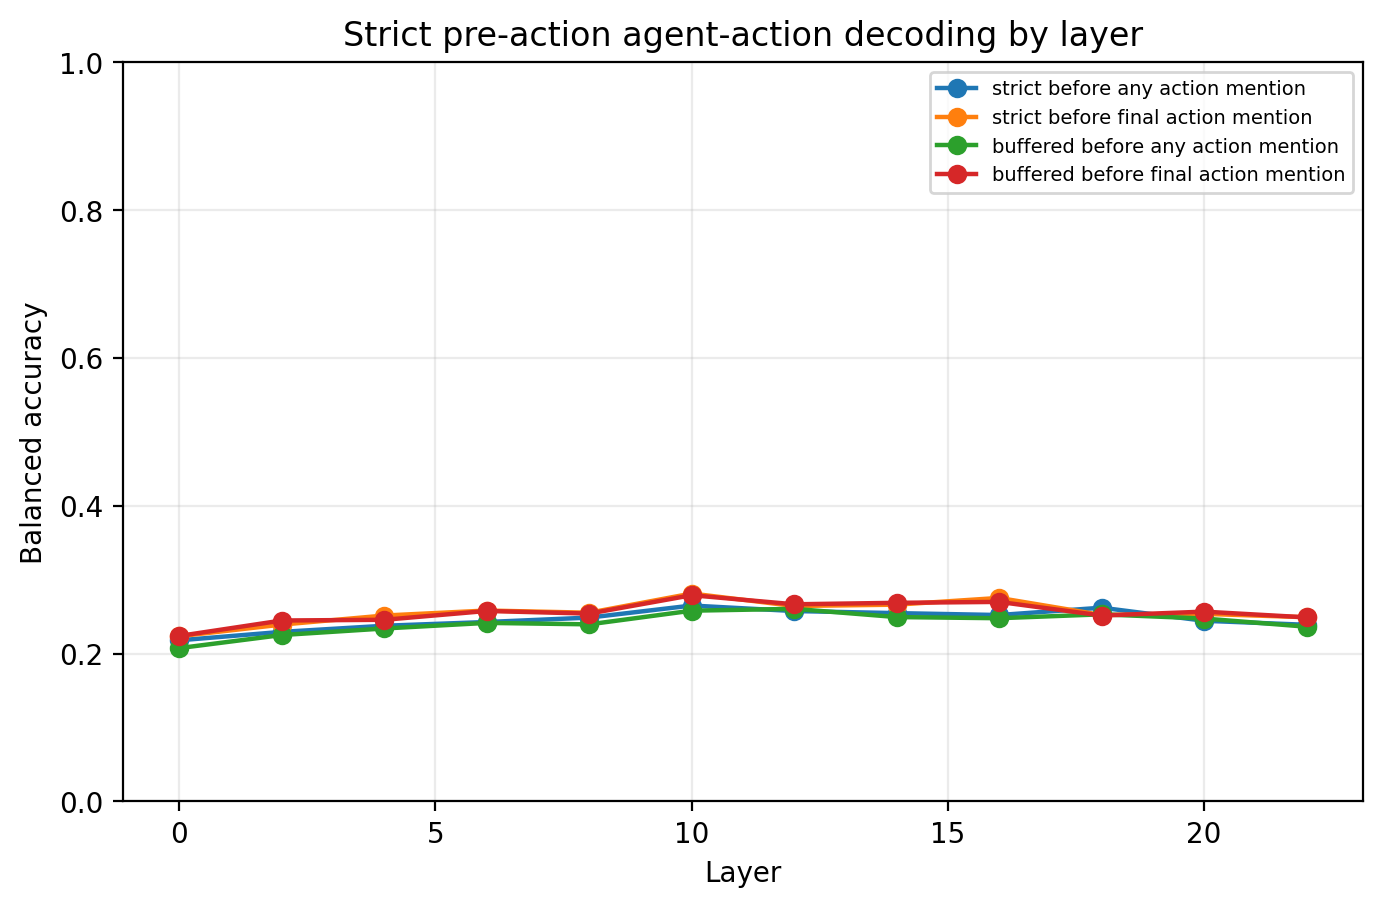

**Final-centroid similarity normalized to first action mention**  \
Axes: x = prefix_token_index / first_action_mention_token_index; y = mean similarity to final-action centroid  \
Color: line/color identifies curve subset if present  \
Saved copy: `figures/activation/report/09_strict_pre_action__final_centroid_similarity_to_first_action_mention.png`

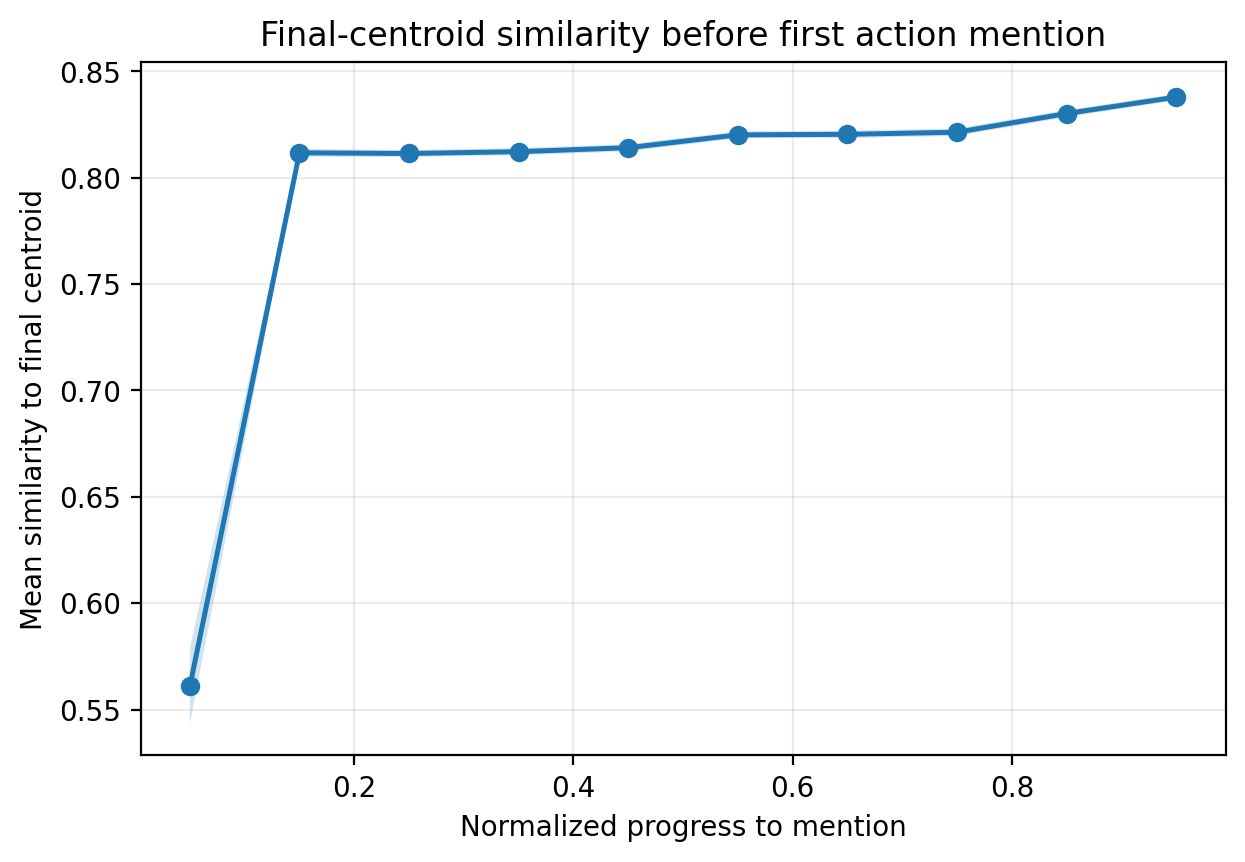

**Strict pre-action coverage**  \
Axes: x = normalized progress bin; y = number of prefix points or decisions  \
Color: bar/line color distinguishes coverage counts  \
Saved copy: `figures/activation/report/09_strict_pre_action__strict_pre_action_coverage.png`

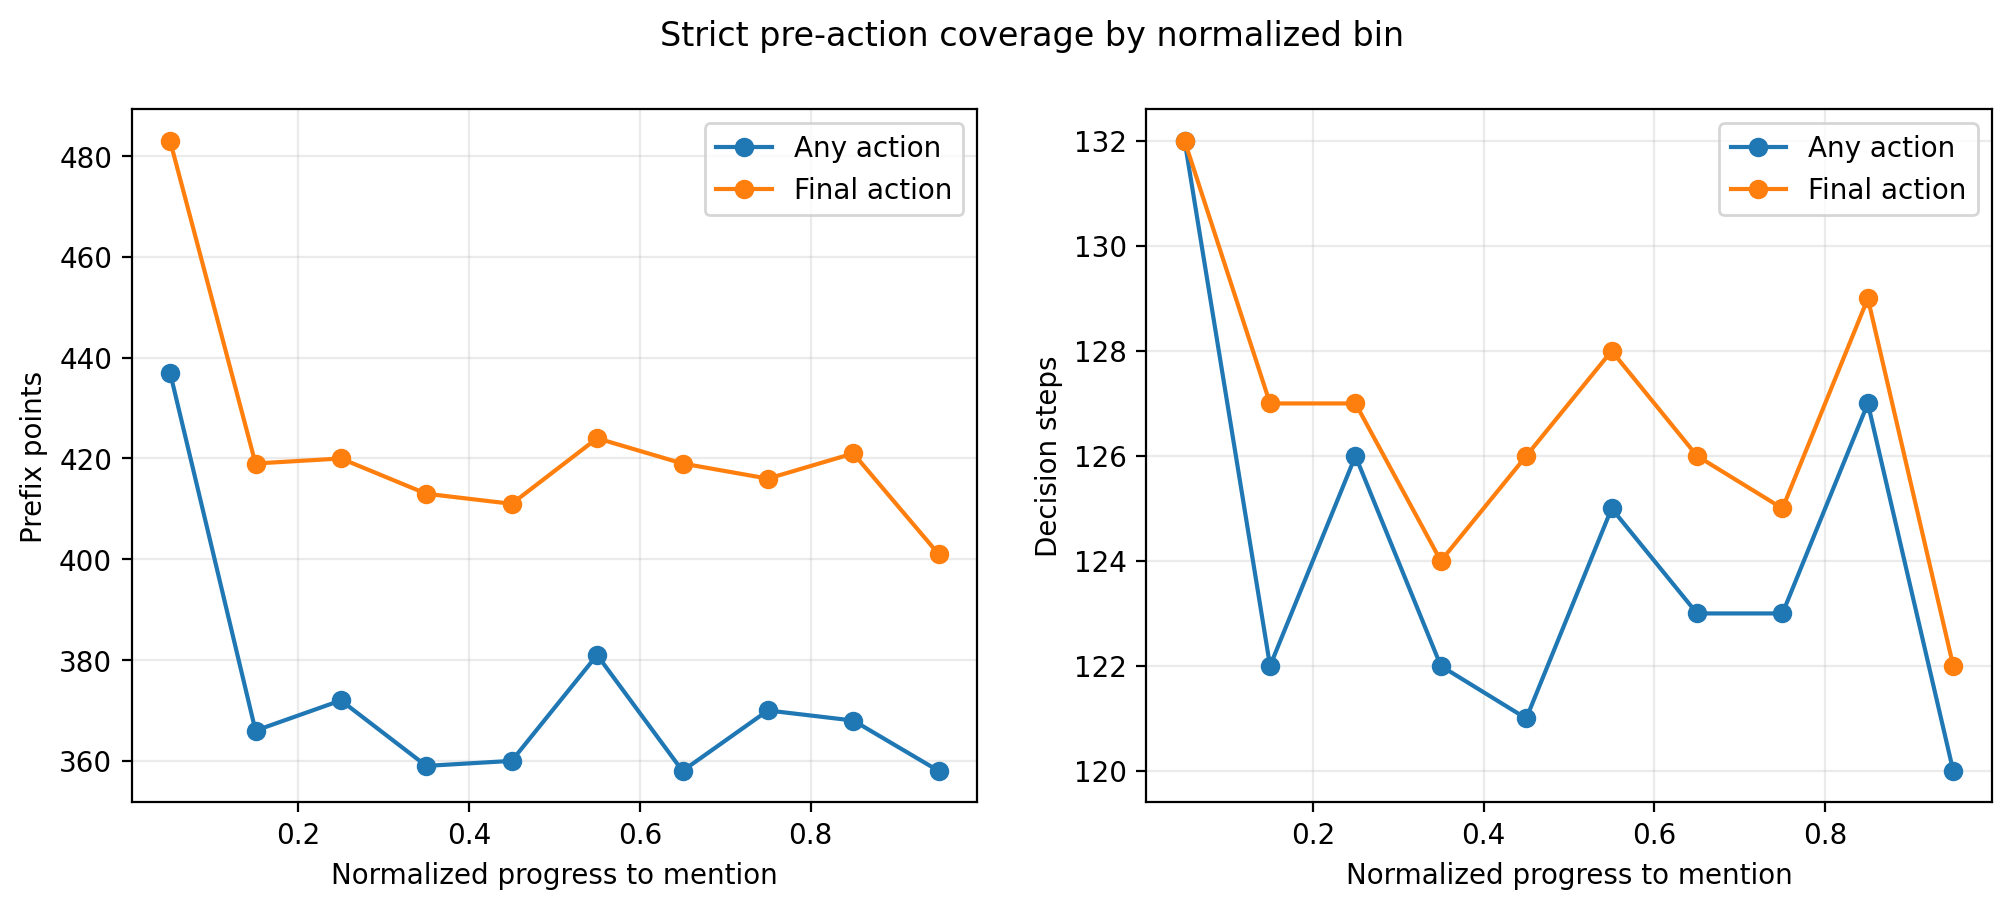

In [10]:
strict_metrics = read_table("outputs/activation/strict_pre_action_activation_metrics.csv")
strict_curves = read_table("outputs/activation/strict_pre_action_activation_curves.csv")
if strict_metrics is not None:
    display(strict_metrics.head())
    display(numeric_summary(strict_metrics, ["balanced_accuracy", "macro_f1", "r2_mean", "r2", "activation_basin_accuracy", "mean_act_sim_final"]))
    SUMMARY["strict_metrics_rows"] = len(strict_metrics)
if strict_curves is not None:
    display(strict_curves.head())

for fig, caption, axis, color in [
    ("figures/activation/strict_pre_action/strict_pre_action_decoding_by_layer.png", "Strict pre-action decoding by layer", "x = layer; y = strict pre-action decoding metric", "line/color identifies strict subset or target"),
    ("figures/activation/strict_pre_action/final_centroid_similarity_to_first_action_mention.png", "Final-centroid similarity normalized to first action mention", "x = prefix_token_index / first_action_mention_token_index; y = mean similarity to final-action centroid", "line/color identifies curve subset if present"),
    ("figures/activation/strict_pre_action/strict_pre_action_coverage.png", "Strict pre-action coverage", "x = normalized progress bin; y = number of prefix points or decisions", "bar/line color distinguishes coverage counts"),
]:
    copy_and_show_figure("09_strict_pre_action", fig, caption, axis, color)


## 10. Controls

Controls test whether the activation-side findings survive label shuffling, progress/length residualization, action-balanced subsampling, CoT-length stratification, and group split sensitivity. The expected shuffled-label result is near chance, while robust true-label metrics should remain above shuffled controls.


Loaded `outputs/activation/activation_control_metrics.csv`: **179 rows x 14 columns**

,control,subset,layer,representation,group_by,target,status,skip_reason,n_rows,n_groups,n_folds,metric,value,covariates
0,true_label_decoding_by_layer,all,0,delta_pre,trajectory_id,agent_action,ok,NaN,9942,10,2.0,agent_action_accuracy,0.288171,NaN
1,true_label_decoding_by_layer,all,0,delta_pre,trajectory_id,agent_action,ok,NaN,9942,10,2.0,agent_action_balanced_accuracy,0.282304,NaN
2,true_label_decoding_by_layer,all,0,delta_pre,trajectory_id,agent_action,ok,NaN,9942,10,2.0,agent_action_macro_f1,0.281722,NaN
3,shuffled_label_decoding_by_layer,all,0,delta_pre,trajectory_id,agent_action_shuffled,ok,NaN,9942,10,2.0,agent_action_accuracy,0.258902,NaN
4,shuffled_label_decoding_by_layer,all,0,delta_pre,trajectory_id,agent_action_shuffled,ok,NaN,9942,10,2.0,agent_action_balanced_accuracy,0.243913,NaN


,count,mean,std,min,25%,50%,75%,max
value,179.0,0.880464,5.513555,-3.164722,0.089745,0.24519,0.282069,44.306161
n_rows,179.0,8989.340782,2145.173889,2305.000000,9942.000000,9942.00000,9942.000000,9942.000000
n_groups,179.0,23.240223,37.182564,9.000000,10.000000,10.00000,10.000000,132.000000


**True vs shuffled decoding by layer**  \
Axes: x = layer; y = balanced action decoding accuracy  \
Color: line color distinguishes true labels from shuffled labels  \
Saved copy: `figures/activation/report/10_controls__true_vs_shuffled_decoding.png`

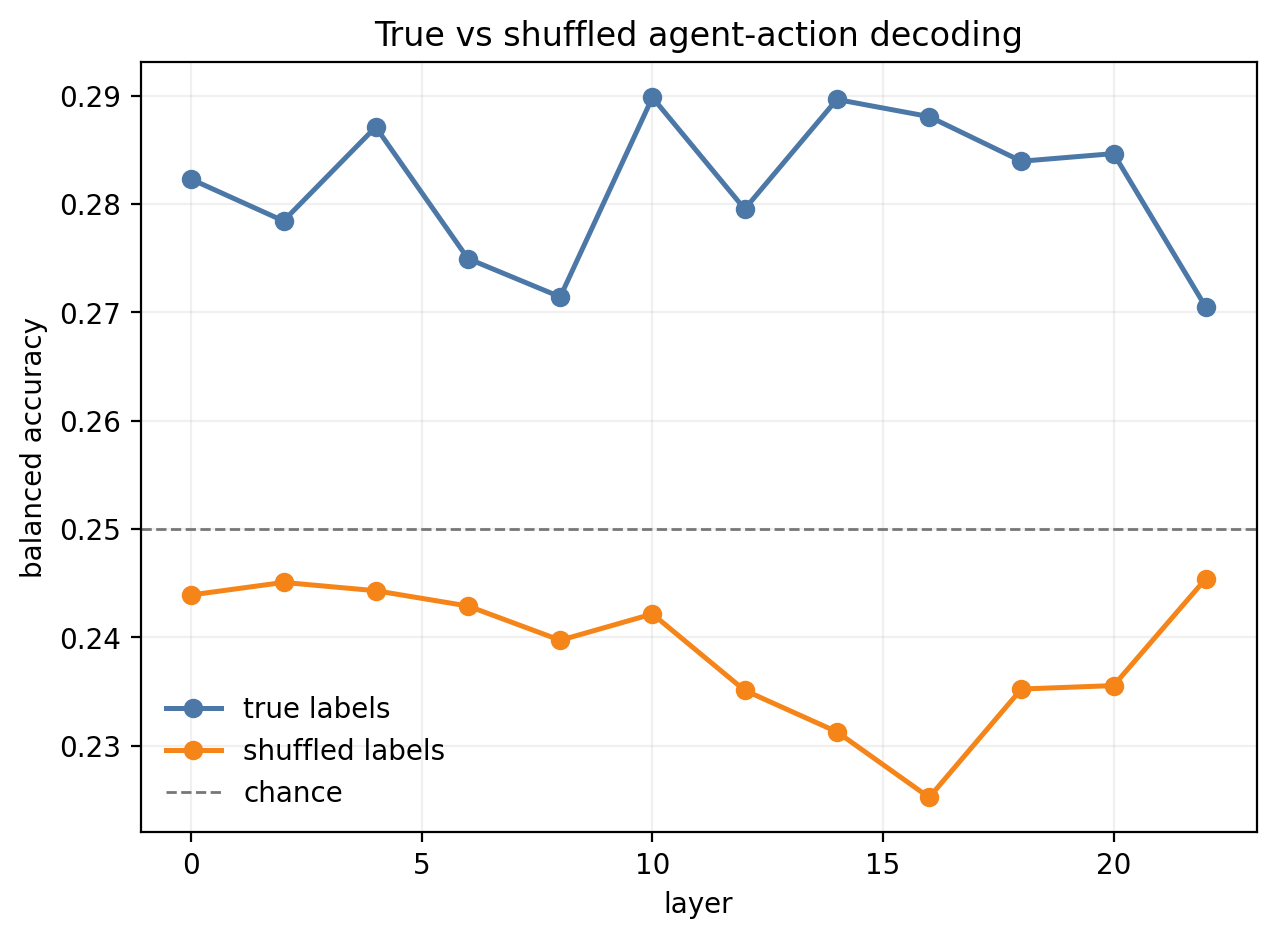

**Original vs progress-residualized PCA by action**  \
Axes: x = PC1; y = PC2 for original and residualized activation features  \
Color: final `agent_action`  \
Saved copy: `figures/activation/report/10_controls__progress_residualized_pca_by_action.png`

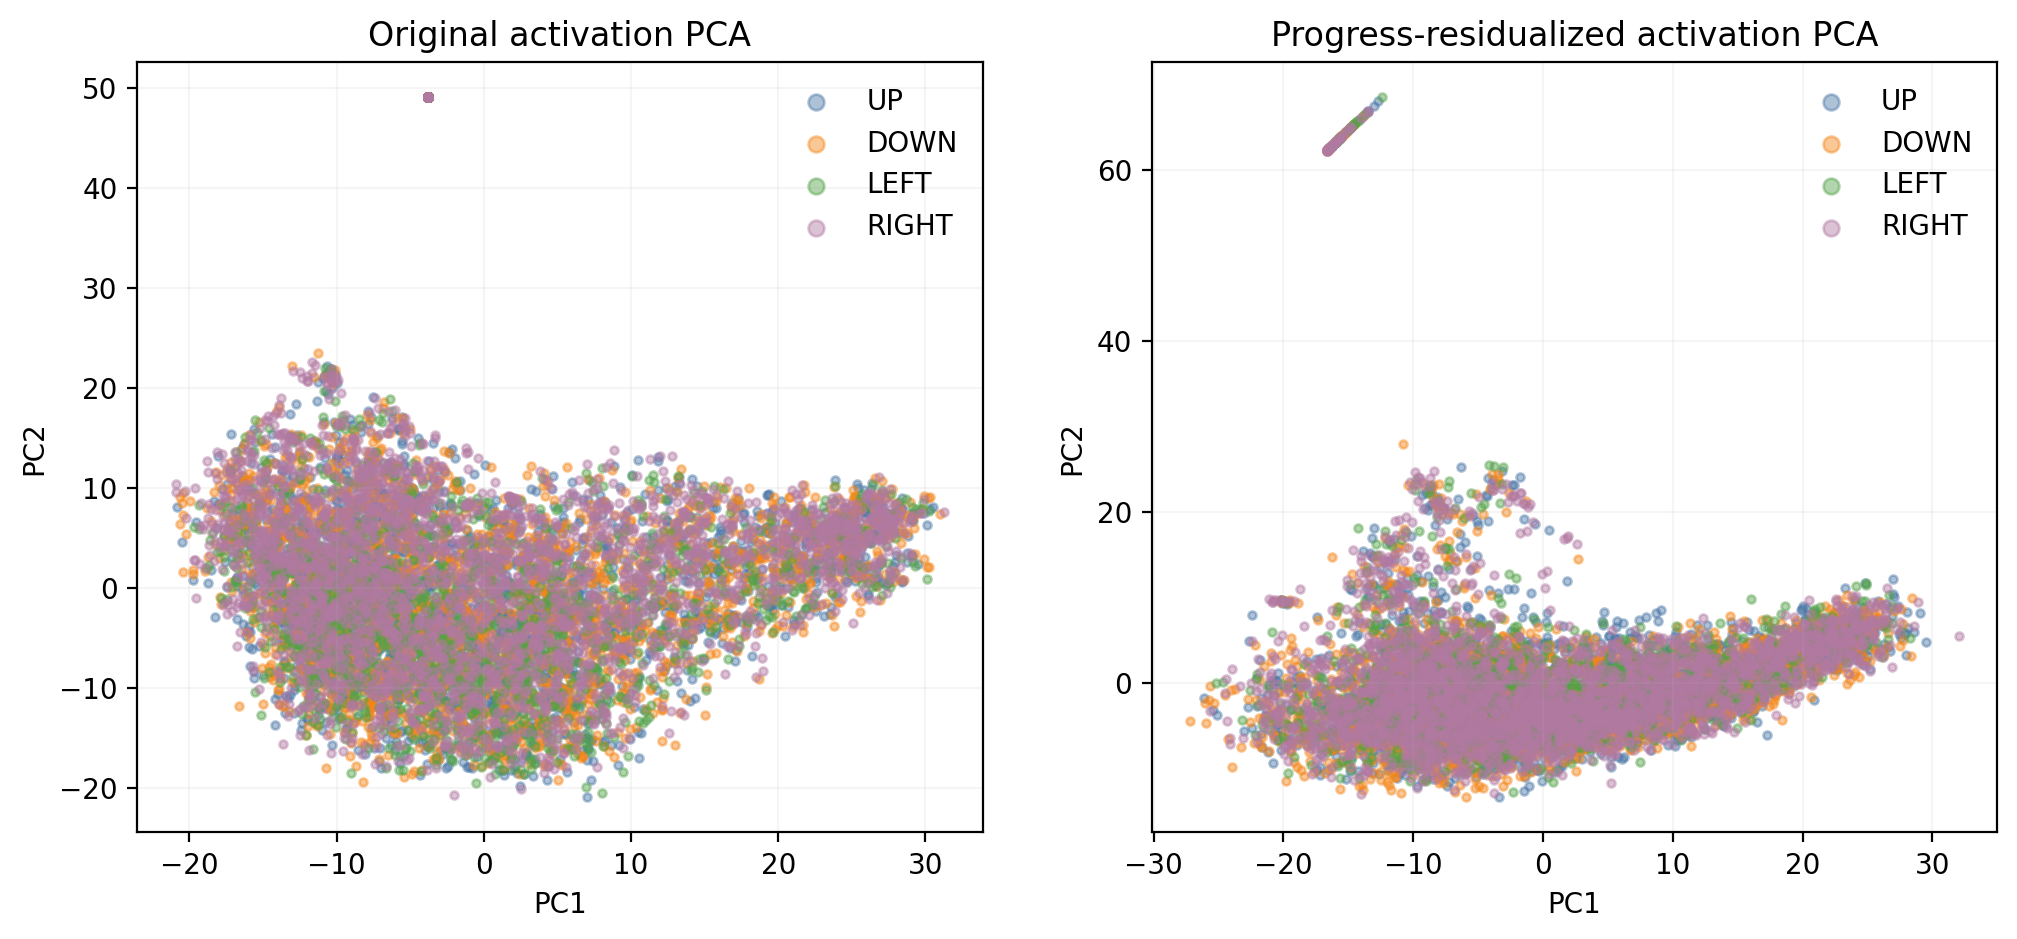

**Action-balanced decoding metrics**  \
Axes: x = metric type; y = metric value  \
Color: bar color distinguishes all decisions from action-balanced subsample  \
Saved copy: `figures/activation/report/10_controls__action_balanced_decoding.png`

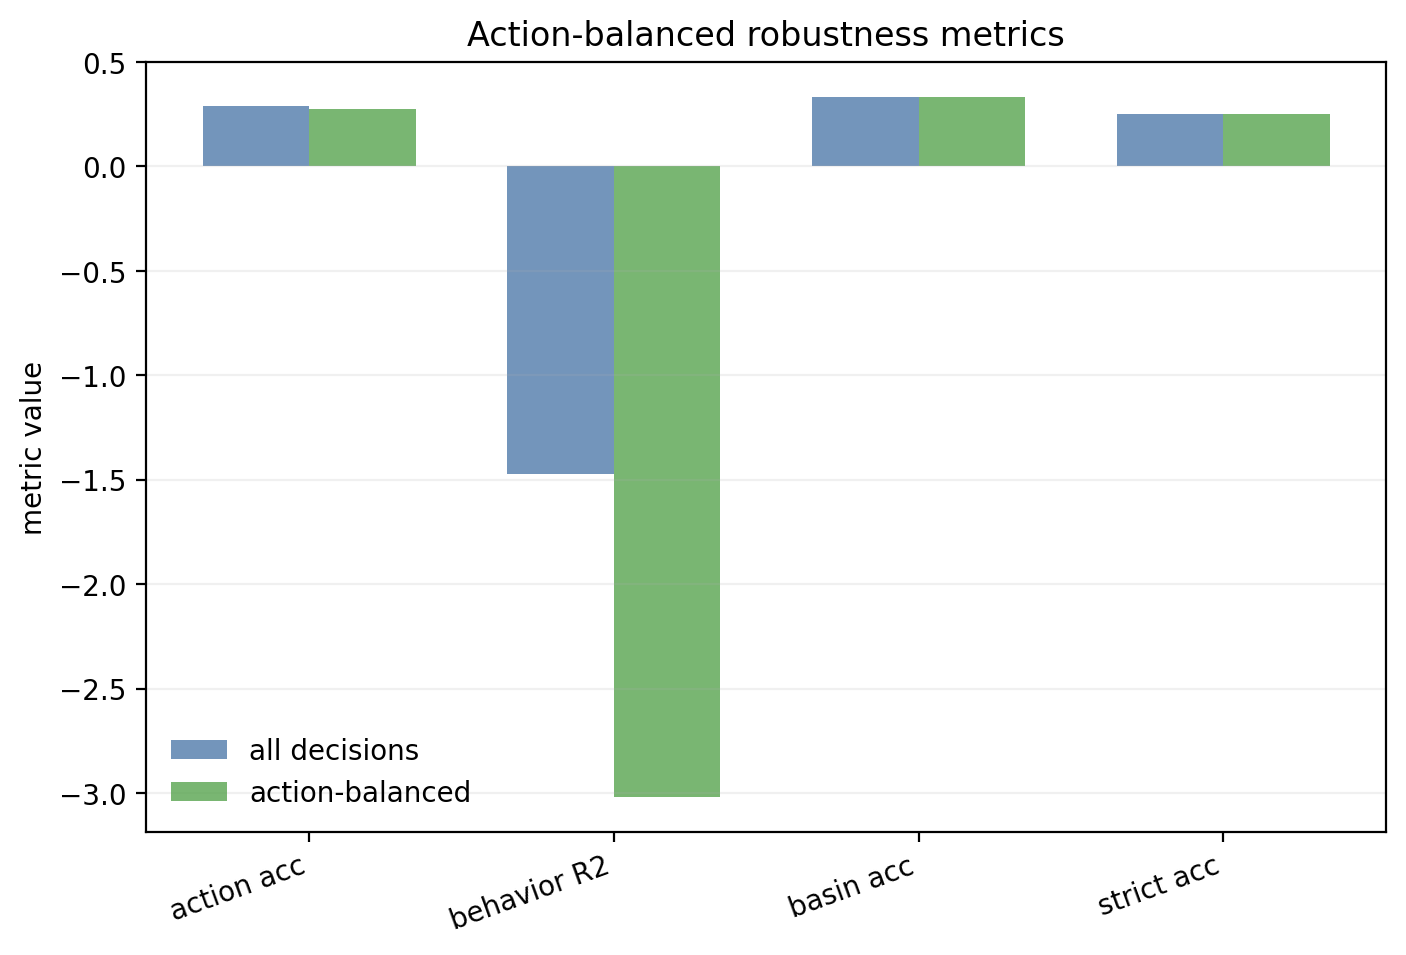

In [11]:
control_metrics = read_table("outputs/activation/activation_control_metrics.csv")
if control_metrics is not None:
    display(control_metrics.head())
    display(numeric_summary(control_metrics, ["value", "n_rows", "n_groups"]))
    SUMMARY["control_metrics_rows"] = len(control_metrics)

for fig, caption, axis, color in [
    ("figures/activation/controls/true_vs_shuffled_decoding.png", "True vs shuffled decoding by layer", "x = layer; y = balanced action decoding accuracy", "line color distinguishes true labels from shuffled labels"),
    ("figures/activation/controls/progress_residualized_pca_by_action.png", "Original vs progress-residualized PCA by action", "x = PC1; y = PC2 for original and residualized activation features", "final `agent_action`"),
    ("figures/activation/controls/action_balanced_decoding.png", "Action-balanced decoding metrics", "x = metric type; y = metric value", "bar color distinguishes all decisions from action-balanced subsample"),
]:
    copy_and_show_figure("10_controls", fig, caption, axis, color)


## 11. Final interpretation

The interpretation should be cautious but strong: activation states appear to carry action-relevant information that changes during reasoning, and several analyses connect these internal trajectories to behavior-side commitment geometry. This does not prove causality, but it gives multiple converging measurements of internal commitment formation.


In [12]:
def metric_lookup(df: pd.DataFrame | None, *, control: str, metric: str, subset: str = "all", group_by: str | None = None) -> float | None:
    if df is None:
        return None
    required = {"control", "metric", "subset", "value", "status"}
    if not required.issubset(df.columns):
        return None
    sub = df[df["control"].astype(str).eq(control) & df["metric"].astype(str).eq(metric) & df["subset"].astype(str).eq(subset)]
    if group_by is not None and "group_by" in sub.columns:
        sub = sub[sub["group_by"].astype(str).eq(group_by)]
    sub = sub[sub["status"].astype(str).eq("ok")]
    if sub.empty:
        return None
    return float(sub["value"].iloc[0])

interpretation_items = []
if pre_post_metrics is not None:
    interpretation_items.append("Pre/post decoding quantifies whether prompt-only and post-reasoning states predict final action.")
if activation_manifold is not None:
    interpretation_items.append("Activation PCA provides an unsupervised view of how prefix states move during reasoning.")
if activation_centroid_scores is not None:
    acc = SUMMARY.get("activation_basin_accuracy")
    if acc is not None:
        interpretation_items.append(f"Activation basin accuracy over all prefix states is approximately {acc:.3f}.")
if strict_metrics is not None:
    rows = strict_metrics[strict_metrics.get("analysis", "").astype(str).eq("agent_action_decoding") & strict_metrics.get("subset", "").astype(str).str.contains("strict_before_any", na=False)] if "analysis" in strict_metrics.columns and "subset" in strict_metrics.columns else pd.DataFrame()
    if len(rows) and "balanced_accuracy" in rows.columns:
        best = rows.sort_values("balanced_accuracy", ascending=False).iloc[0]
        interpretation_items.append(f"Best strict-before-any action decoding balanced accuracy is {float(best['balanced_accuracy']):.3f} at layer {int(best['layer'])}.")
if control_metrics is not None:
    true_acc = metric_lookup(control_metrics, control="selected_layer_true_decoding", metric="agent_action_balanced_accuracy")
    shuffled_acc = metric_lookup(control_metrics, control="shuffled_label_centroid", metric="basin_accuracy_accuracy")
    if true_acc is not None:
        interpretation_items.append(f"Selected-layer action decoding balanced accuracy is {true_acc:.3f} under trajectory-level grouped splits.")
    if shuffled_acc is not None:
        interpretation_items.append(f"Shuffled-label centroid basin accuracy is {shuffled_acc:.3f}, near chance for four actions.")

display(Markdown("\n".join(f"- {item}" for item in interpretation_items) if interpretation_items else "No interpretation metrics available."))
SUMMARY["interpretation_items"] = interpretation_items


- Pre/post decoding quantifies whether prompt-only and post-reasoning states predict final action.
- Activation PCA provides an unsupervised view of how prefix states move during reasoning.
- Activation basin accuracy over all prefix states is approximately 0.333.
- Best strict-before-any action decoding balanced accuracy is 0.265 at layer 10.
- Selected-layer action decoding balanced accuracy is 0.288 under trajectory-level grouped splits.
- Shuffled-label centroid basin accuracy is 0.251, near chance for four actions.

## 12. Limitations

- Activation at CoT token positions is not identical to the activation used for the final JSON decision readout.
- Behavior-side q was measured using forced final-JSON scoring, not by sampling final answers.
- Pre-action means no explicit action token was generated; implicit coordinate, path, or plan descriptions may still reveal the action.
- This is observational. It does not prove the activation geometry causally determines the final action.
- A mismatched prompt/CoT activation control would require additional activation extraction and is not performed here.


## 13. Save final markdown report

The final cell writes `outputs/activation/reports/final_activation_commitment_report.md` and records all copied report figures under `figures/activation/report/`.


In [13]:
def fmt_value(value):
    if value is None:
        return "unavailable"
    if isinstance(value, float):
        return f"{value:.4f}"
    return str(value)

report_lines = []
report_lines.extend([
    "# Final Activation Commitment Report",
    "",
    "## 1. Introduction",
    "",
    "Behavior-side analysis showed that action commitment increases and sometimes switches during CoT reasoning. Activation-side analysis asks whether this behavioral commitment is reflected in internal activation trajectories. This report uses existing activation outputs only; no activation extraction is performed here.",
    "",
    "## 2. Data",
    "",
])
for key, value in SUMMARY.get("data_summary", {}).items():
    report_lines.append(f"- {key}: {value}")
if "action_distribution" in SUMMARY:
    report_lines.append(f"- action distribution by decision: {SUMMARY['action_distribution']}")
if "token_type_counts" in SUMMARY:
    report_lines.append(f"- token type counts: {SUMMARY['token_type_counts']}")

report_lines.extend([
    "",
    "## 3. Activation Representation",
    "",
    "We define `h_pre` as the pre-reasoning activation, `h_k` as the activation at CoT prefix/token position `k`, and `h_post` as the post-reasoning activation. The main representation is `delta_pre = h_k - h_pre`, which isolates reasoning-time movement away from the prompt-induced baseline. Raw activation and velocity are robustness representations: raw preserves absolute state, while velocity emphasizes local movement between consecutive prefixes.",
    "",
    "## 4. Layer-wise Decoding",
    "",
])
if layer_sweep_metrics is None:
    report_lines.append("- `outputs/activation/layer_sweep_metrics.csv` was not present, so this notebook skipped direct layer-sweep metric tables and missing layer-sweep figures.")
else:
    report_lines.append(f"- Loaded layer-sweep metrics with {len(layer_sweep_metrics):,} rows.")

report_lines.extend([
    "",
    "## 5. Activation Manifold",
    "",
])
if activation_manifold is not None:
    report_lines.append(f"- Activation manifold rows: {len(activation_manifold):,}")
    report_lines.append("- Axes: x = first activation PCA component; y = second activation PCA component. Each point is one CoT prefix activation state.")
else:
    report_lines.append("- Activation manifold output was unavailable.")

report_lines.extend([
    "",
    "## 6. Activation-Behavior Alignment",
    "",
])
if activation_behavior_alignment_metrics is not None:
    report_lines.append(f"- Loaded activation-behavior alignment metrics with {len(activation_behavior_alignment_metrics):,} rows.")
    report_lines.append("- These analyses test whether activations linearly predict behavior q distributions and whether activation/behavior manifolds share geometry.")
else:
    report_lines.append("- Activation-behavior alignment metrics were unavailable.")

report_lines.extend([
    "",
    "## 7. Action Centroids and Activation Basins",
    "",
    "Action centroids are action-conditioned activation prototypes. A prefix belongs to the activation basin of the nearest/highest-similarity action centroid. Activation lock-in is compared with behavior-side lock-in from q-distribution dynamics.",
])
if SUMMARY.get("activation_basin_accuracy") is not None:
    report_lines.append(f"- Overall activation basin accuracy across prefix states: {SUMMARY['activation_basin_accuracy']:.4f}")

report_lines.extend([
    "",
    "## 8. Pre-reasoning vs Post-reasoning",
    "",
    "If `h_pre` predicts action, the prompt induces an initial action prior. If `h_post` predicts action more strongly, CoT reasoning sharpens internal action commitment. If `h_post - h_pre` predicts action, the reasoning-induced state change is action-specific.",
    "",
    "## 9. Strict Pre-action Activation",
    "",
    "Strict pre-action analysis asks whether internal final-action information is visible before any explicit lexical action token. This is not the same as proving there is no implicit coordinate or path evidence in the text.",
])
for item in SUMMARY.get("interpretation_items", []):
    report_lines.append(f"- {item}")

report_lines.extend([
    "",
    "## 10. Controls",
    "",
])
if control_metrics is not None:
    true_acc = metric_lookup(control_metrics, control="selected_layer_true_decoding", metric="agent_action_balanced_accuracy")
    resid_acc = metric_lookup(control_metrics, control="progress_residualized", metric="agent_action_balanced_accuracy")
    balanced_acc = metric_lookup(control_metrics, control="action_balanced_subsample", metric="agent_action_balanced_accuracy")
    traj_acc = metric_lookup(control_metrics, control="group_split_sensitivity", metric="agent_action_balanced_accuracy", group_by="trajectory_id")
    decision_acc = metric_lookup(control_metrics, control="group_split_sensitivity", metric="agent_action_balanced_accuracy", group_by="decision_id")
    report_lines.extend([
        f"- Selected-layer true action decoding balanced accuracy: {fmt_value(true_acc)}",
        f"- Progress-residualized action decoding balanced accuracy: {fmt_value(resid_acc)}",
        f"- Action-balanced action decoding balanced accuracy: {fmt_value(balanced_acc)}",
        f"- Trajectory-level split action decoding balanced accuracy: {fmt_value(traj_acc)}",
        f"- Decision-level split action decoding balanced accuracy: {fmt_value(decision_acc)}",
    ])
else:
    report_lines.append("- Control metrics were unavailable.")

report_lines.extend([
    "",
    "## 11. Final Interpretation",
    "",
    "The results support a cautious but strong interpretation: the prompt can induce an initial action prior; CoT reasoning changes the activation state relative to pre-reasoning; action commitment becomes increasingly decodable from activation; and activation geometry can be compared with behavior-side commitment geometry. Strict pre-action analyses specifically test whether internal commitment is visible before explicit action words, while permanent activation lock-in can be compared with behavioral permanent lock-in.",
    "",
    "## 12. Limitations",
    "",
    "- Activation at CoT token positions is not identical to final JSON decision-readout activation.",
    "- Behavior q was measured using forced final JSON scoring.",
    "- Pre-action means no explicit action token, but implicit path descriptions may still reveal action.",
    "- Observational analysis does not prove causality.",
    "- A mismatched prompt/CoT activation control would require additional activation extraction.",
    "",
    "## Reproduced Figures",
    "",
])

if FIGURE_RECORDS:
    for rec in FIGURE_RECORDS:
        report_lines.extend([
            f"### {rec['caption']}",
            "",
            f"![{rec['caption']}]({rec['markdown_rel']})",
            "",
            f"- Section: {rec['section']}",
            f"- Axes: {rec['axis_note']}",
            f"- Color: {rec['color_note']}",
            f"- Source: `{rec['source']}`",
            "",
        ])
else:
    report_lines.append("No figures were reproduced because all requested source figures were missing.")

if SECTION_NOTES:
    report_lines.extend(["", "## Skipped or Missing Optional Outputs", ""])
    for note in SECTION_NOTES:
        report_lines.append(f"- {note}")

REPORT_MD_PATH.write_text("\n".join(report_lines) + "\n")
display(Markdown(f"Wrote final markdown report: `{rel(REPORT_MD_PATH)}`"))
display(Markdown(f"Copied {len(FIGURE_RECORDS)} figures to `{rel(REPORT_FIG_DIR)}`"))


Wrote final markdown report: `outputs/activation/reports/final_activation_commitment_report.md`

Copied 23 figures to `figures/activation/report`